# Diabetes Screening Classifier: WHO STEPS Kenya 2015
**DSA 8401 Applied Machine Learning: capstone, modelling notebook**
Kelvin Ngigi Kamau (Reg. 192743), MSc Data Science & Analytics, Strathmore University

## 1. Problem statement
**Problem.** Kenya's 2015 STEPS survey measured fasting blood glucose in a nationally representative adult sample. Undiagnosed diabetes is common and a laboratory glucose test is expensive at community level. The goal is to rank people by diabetes risk so that a community health worker can decide who to refer for a confirmatory fasting-glucose test.


**NB** The model only uses **cheap, non-laboratory information** (questionnaire answers, blood pressure, height/weight/waist/hip)

**Target.** `1` = diabetes present, `0` = no diabetes (defined in section 3 from the WHO STEPS definition).

**Design principles that drove every decision below**
1. *Nothing was fitted on data later used for evaluation.* Every statistic (imputation values, scaling, category lists, column-drop decisions, hyper-parameters) was learned from the **training set only**, and anything learned from data sat inside the cross-validation fold.
2. *The survey design was respected.* Respondents are clustered in 200 primary sampling units (PSUs); people in the same cluster are not independent, so splits and cross-validation were **grouped by PSU**.
3. *A rare outcome called for appropriate metrics.* About 3% of respondents are positive, so accuracy is uninformative. PR-AUC (primary), ROC-AUC, Brier score and calibration were used, and the operating threshold was chosen deliberately rather than defaulting to 0.5.
4. *Missingness is information.* The **mechanism** of each missing value (structural / MCAR / MAR / MNAR) was diagnosed before a treatment was chosen.
5. *Strong baselines came first.* Every complex model had to beat a prevalence-only dummy and a small clinical logistic regression.

**Requirement map (requirement → where it is addressed)**

| Requirement | Section |
|---|---|
| Target 0 = no diabetes, 1 = diabetes, best definition | 3 |
| Drop columns with ≥ 80% missing, with justification of why they are missing | 6, 6.1 |
| Impute columns with < 20% missing, justified per mechanism | 8, 8.1 |
| 70% train / 15% validation / 15% test, no leakage | 5, 7, 14 |
| ≥ 3 models, with the transformations each needs | 9, 11 |
| Leakage proof (audit, ablation, label-shuffle canary) | 14 |
| Evaluation, calibration, threshold, final test, explainability, limitations | 10, 12, 13, 15–18 |

In [27]:
%matplotlib inline
import warnings, re, json, math, time, random
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import sklearn, lightgbm, optuna, scipy
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_curve, confusion_matrix)
from lightgbm import LGBMClassifier

SEED = 42
np.random.seed(SEED); random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_rows", 200, "display.max_colwidth", 70)
sns.set_theme(style="whitegrid", context="notebook")
print({m.__name__: m.__version__ for m in (np, pd, sklearn, lightgbm, optuna, scipy)})

DATA_PATH = "Kenya2015.csv"   # relative to the notebook folder

{'numpy': '2.1.0', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'lightgbm': '4.5.0', 'optuna': '5.1.0', 'scipy': '1.18.1'}


## 2. Data: loading and structure
`Kenya2015.csv` is the raw STEPS file with columns renamed to match `Section__CODE_Description` (the code is the questionnaire item). Values are unchanged.

In [28]:
raw_full = pd.read_csv(DATA_PATH)
SECTION = {c.split("__", 1)[1]: c.split("__", 1)[0] for c in raw_full.columns}
raw = raw_full.copy(); raw.columns = [c.split("__", 1)[1] for c in raw.columns]
assert raw.columns.is_unique and raw.shape == (4500, 233)

def col(code):
    """Return the unique column whose questionnaire code (text before first underscore) equals `code`."""
    m = [c for c in raw.columns if c.split("_")[0] == code]
    assert len(m) == 1, (code, m)
    return m[0]

print("shape:", raw.shape)
print("columns per questionnaire section:")
display(pd.Series(SECTION).value_counts().rename("n_columns").to_frame().T)
print("PSUs (clusters):", raw["PSU_Cluster"].nunique(), "| respondents per PSU: min/median/max =",
      raw["PSU_Cluster"].value_counts().agg(["min", "median", "max"]).tolist())

shape: (4500, 233)
columns per questionnaire section:


,Oral_Health,Tobacco_Smoking,Alcohol,Physical_Activity,Tobacco_Smokeless,Diet_Salt_Fat,Step2_Blood_Pressure,Injury,Lifestyle_Advice,Demographics,Step3_Blood_Glucose,Step2_Height_Weight,History_Diabetes,Survey_Design_Derived,History_Cholesterol,History_Raised_BP,Violence,Diet_Fruit_Veg,Survey_Info,Unintentional_Injury,History_CVD,Step3_Blood_Lipids,Cervical_Cancer_Screening
n_columns,31,27,22,22,17,16,12,9,8,8,7,7,7,6,6,6,5,4,3,3,3,3,1


PSUs (clusters): 200 | respondents per PSU: min/median/max = [7.0, 23.0, 29.0]


## 3. Choosing the target
**WHO STEPS definition of raised blood glucose / diabetes:** fasting plasma glucose **≥ 7.0 mmol/L (126 mg/dL)** *or* currently on diabetes medication. We adopted it because
* it is the survey's own, internationally comparable definition (so our prevalence can be checked against published STEPS tables);
* it uses a **measured** biomarker rather than self-report, so the label does not depend on whether a person had ever been tested (self-reported "told you have diabetes" misses the undiagnosed, who are exactly who a screening tool must find);
* adding the medication clause correctly labels treated, well-controlled patients whose glucose is normal *because* of treatment.

**Alternatives considered and rejected:** (a) fasting glucose ≥ 6.1 (impaired fasting glucose + diabetes) → turns the task into "pre-diabetes or worse" and about 5.7% prevalence; a different clinical question. (b) Self-reported diagnosis only → ignores undiagnosed cases and sits in the history block that had to be excluded from the features (section 7). (c) A continuous glucose regression target → loses the clinically meaningful cut-off.

**A label needs a trustworthy value, so respondents are three-state:**
* **Positive (1):** on diabetes medication (items B6, H8 or H9), *or* fasted and glucose ≥ 7.0.
* **Negative (0):** fasted (B1 = no food/drink in the last 8 h), glucose measured and < 7.0, and not on medication.
* **Not labelled → excluded:** no glucose reading, or *not fasted* and not on medication. A non-fasting glucose is physiologically higher (mean 5.22 vs 4.62 mmol/L in this data, among respondents not on medication), so calling such a person "negative" would have injected label noise.

,step,n
0,Respondents in survey file,4500
1,- no glucose reading (Step 3 not completed) and not on medication,320
2,"- glucose present but NOT fasted, and not on medication",90
3,Labelled respondents used for modelling,4090
4,of which positive (diabetes = 1),116
5,of which negative (diabetes = 0),3974


Prevalence in labelled sample: 2.84%   (positives via medication only: 24; via glucose >= 7 only: 72)
Non-fasting respondents with glucose >= 7 (would have been false labels): 10
Respondents who say they were told they have diabetes, are not on medication and have glucose < 7 (ambiguous, e.g. diet-controlled; labelled 0 by the WHO rule): 27


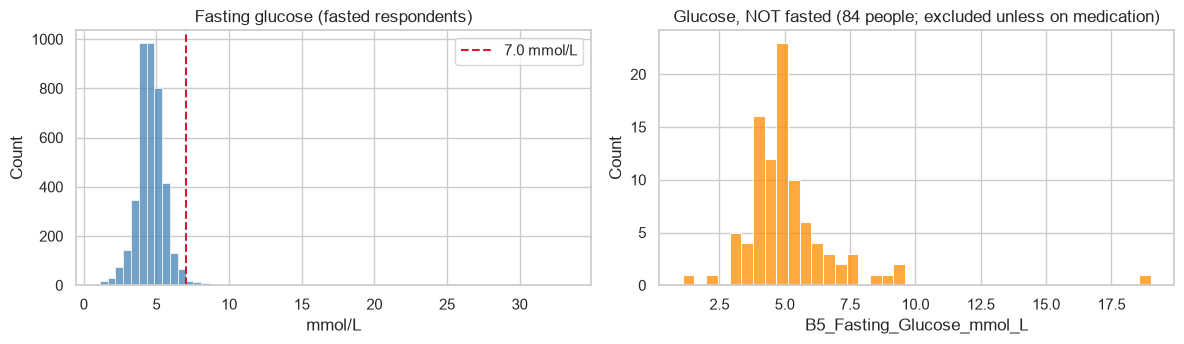

In [29]:
g       = raw[col("B5")]
fasted  = raw[col("B1")].eq(2)          # B1 = 2 -> did NOT eat/drink in the past 8 h
on_med  = (raw[col("B6")].eq(1) | raw[col("H8")].eq(1) | raw[col("H9")].eq(1))
pos     = on_med | (fasted & g.ge(7.0))
neg     = fasted & g.notna() & g.lt(7.0) & ~on_med
y_all   = pd.Series(np.where(pos, 1.0, np.where(neg, 0.0, np.nan)), index=raw.index, name="diabetes")

flow = pd.DataFrame([
    ("Respondents in survey file", len(raw)),
    ("  - no glucose reading (Step 3 not completed) and not on medication", int((g.isna() & ~on_med).sum())),
    ("  - glucose present but NOT fasted, and not on medication", int((g.notna() & ~fasted & ~on_med).sum())),
    ("Labelled respondents used for modelling", int(y_all.notna().sum())),
    ("    of which positive (diabetes = 1)", int((y_all == 1).sum())),
    ("    of which negative (diabetes = 0)", int((y_all == 0).sum())),
], columns=["step", "n"])
display(flow)
print(f"Prevalence in labelled sample: {y_all.mean():.2%}   (positives via medication only: "
      f"{int((on_med & ~(fasted & g.ge(7.0))).sum())}; via glucose >= 7 only: {int((~on_med & fasted & g.ge(7.0)).sum())})")
print("Non-fasting respondents with glucose >= 7 (would have been false labels):", int((~fasted & g.ge(7.0)).sum()))
told = raw[col("H7a")].eq(1)
print("Respondents who say they were told they have diabetes, are not on medication and have glucose < 7 "
      "(ambiguous, e.g. diet-controlled; labelled 0 by the WHO rule):", int((told & ~on_med & neg).sum()))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(g[fasted], bins=60, ax=ax[0], color="steelblue"); ax[0].axvline(7.0, color="crimson", ls="--", label="7.0 mmol/L")
ax[0].set_title("Fasting glucose (fasted respondents)"); ax[0].set_xlabel("mmol/L"); ax[0].legend()
sns.histplot(g[~fasted & g.notna()], bins=40, ax=ax[1], color="darkorange"); ax[1].set_title("Glucose, NOT fasted (84 people; excluded unless on medication)")
plt.tight_layout(); plt.show()

## 4. Data cleaning
Cleaning had two kinds of operation:
* **Rule-based recoding that learns nothing from the data** (convert a documented "don't know" code to missing, reject a physiologically impossible value, turn 1/2 into 1/0). The result for one respondent never depends on any other respondent, so it is **identical whether done before or after the split** and cannot leak.
* **Data-dependent steps** (which columns to drop, imputation values, scaling, category lists, hyper-parameters). These **are fitted on the training set only**, after the split.

This section fixed the following (all documented in the STEPS questionnaire coding):
1. **Disguised missing values.** STEPS stores "don't know / refused" as `77`, `777`, `88`, `888` and a few single-digit codes (`7`, `8`). Treated as numbers they would silently corrupt means (e.g. a "weight" of 888.8 kg). They were converted to missing. Free-text "specify" columns use `"."` as a placeholder for "nothing written" → missing.
2. **Invalid codes** (e.g. `0` in a yes/no item whose codes are 1/2) → missing.
3. **Physiological plausibility.** Impossible readings (systolic BP of 0, height 888 cm, waist 0 cm) → missing, using generous clinical ranges.
4. **Binary recode** of 1 = yes / 2 = no items to 1/0, so the model sees one consistent convention.

In [30]:
ID_COLS  = [col(c) for c in ["Participant", "M1", "M2", "M10ab", "M13", "B2", "B3"]]     # people / device / technician identifiers
DESIGN   = ["PSU_Cluster", "Stratum", "Weight_Step1", "Weight_Step2", "Weight_Step3", "Age_Range_Derived"]
STEP3    = [c for c in raw.columns if SECTION[c].startswith("Step3")]                     # blood glucose + lipid block
RANGES = {col("M4a"): (60, 270), col("M5a"): (60, 270), col("M6a"): (60, 270),             # systolic BP mmHg
          col("M4b"): (30, 150), col("M5b"): (30, 150), col("M6b"): (30, 150),             # diastolic BP mmHg
          col("M16a"): (30, 220), col("M16b"): (30, 220), col("M16c"): (30, 220),          # heart rate bpm
          col("M11"): (100, 220), col("M12"): (25, 250), col("M14"): (40, 200), col("M15"): (50, 200)}  # cm, kg, cm, cm
# single-digit "don't know / refused / invalid" codes for ordinal & categorical items (from the questionnaire coding)
LIKERT_DK = {col("D5"): [0, 7], col("D6"): [7], col("D8"): [7], col("V1"): [7], col("V2"): [7], col("V3"): [7],
             col("V8"): [7, 8], col("V11"): [0, 7, 8], col("O1"): [7]}
SENTINELS = [77, 777, 7777, 88, 888, 8888]
WORK_NUM = [c for c in raw.columns if pd.api.types.is_numeric_dtype(raw[c])
            and c not in ID_COLS + DESIGN + STEP3 and c not in RANGES]

def clean_raw(df):
    """Rule-based, row-wise cleaning."""
    d, log = df.copy(), []
    def note(c, rule, n):
        if n: log.append((c, rule, int(n)))
    # 1a. text placeholders -> NaN
    for c in d.columns:
        if not pd.api.types.is_numeric_dtype(d[c]):
            s = d[c].astype("string").str.strip()
            s = s.mask(s.isin([".", "", "nan", "NA"]))
            note(c, "text placeholder '.' -> NaN", s.isna().sum() - d[c].isna().sum())
            d[c] = s.astype(object).where(s.notna(), np.nan)
    # 1b. numeric sentinels (77/777/88/888...) -> NaN
    for c in WORK_NUM:
        m = d[c].isin(SENTINELS); note(c, "sentinel 77/777/88/888 -> NaN", m.sum()); d.loc[m, c] = np.nan
    for c, codes in LIKERT_DK.items():
        m = d[c].isin(codes); note(c, f"don't-know/invalid code {codes} -> NaN", m.sum()); d.loc[m, c] = np.nan
    # 3. plausibility ranges
    for c, (lo, hi) in RANGES.items():
        m = d[c].notna() & ~d[c].between(lo, hi); note(c, f"implausible (outside {lo}-{hi}) -> NaN", m.sum()); d.loc[m, c] = np.nan
    d["C4_Years_Of_Schooling"] = d["C4_Years_Of_Schooling"].mask(d["C4_Years_Of_Schooling"] > 25)  # 77 handled above; defensive
    # 4. binary 1/2 -> 1/0 (any other code is invalid -> NaN)
    for c in BIN_COLS:
        m = d[c].notna() & ~d[c].isin([1, 2]); note(c, "invalid code in yes/no item -> NaN", m.sum())
        d[c] = d[c].map({1.0: 1.0, 2.0: 0.0})
    d["Urban"]  = d["X2a_Residence_Rural1_Urban2"].map({1: 0.0, 2: 1.0})
    d["Female"] = d["C1_Sex"].map({"Women": 1.0, "Men": 0.0})
    return d, pd.DataFrame(log, columns=["column", "rule", "n_cells"])

# Which numeric items are yes/no? Decided from the questionnaire coding: >= 98% of answers are 1 or 2 (after removing DK codes).
_tmp = raw.copy()
for c in WORK_NUM: _tmp.loc[_tmp[c].isin(SENTINELS), c] = np.nan
for c, codes in LIKERT_DK.items(): _tmp.loc[_tmp[c].isin(codes), c] = np.nan
BIN_COLS = [c for c in WORK_NUM if c != "X2a_Residence_Rural1_Urban2" and _tmp[c].nunique() <= 6
            and _tmp[c].dropna().isin([1, 2]).mean() >= 0.98]
clean, CLEAN_LOG = clean_raw(raw)
print(f"{len(BIN_COLS)} yes/no items recoded to 1/0;  {len(CLEAN_LOG)} cleaning actions logged")
display(CLEAN_LOG.groupby("rule").agg(columns=("column", "nunique"), cells=("n_cells", "sum")).sort_values("cells", ascending=False))
print("Largest single cleaning actions:"); display(CLEAN_LOG.sort_values("n_cells", ascending=False).head(12))

87 yes/no items recoded to 1/0;  117 cleaning actions logged


,columns,cells
rule,,
text placeholder '.' -> NaN,10,44649
sentinel 77/777/88/888 -> NaN,70,2542
don't-know/invalid code [7] -> NaN,6,110
implausible (outside 40-200) -> NaN,1,106
implausible (outside 50-200) -> NaN,1,94
invalid code in yes/no item -> NaN,17,57
implausible (outside 60-270) -> NaN,3,25
implausible (outside 30-150) -> NaN,3,14
implausible (outside 100-220) -> NaN,1,13


Largest single cleaning actions:


,column,rule,n_cells
6,V12other_Violent_Injury_Cause_Specify,text placeholder '.' -> NaN,4498
1,T14other_Other_Smokeless_Specify,text placeholder '.' -> NaN,4495
3,D12other_Oil_Specify,text placeholder '.' -> NaN,4489
0,T5other_Other_Smoked_Specify,text placeholder '.' -> NaN,4485
7,V13other_Relationship_Specify,text placeholder '.' -> NaN,4480
5,V7other_Injury_Location_Specify,text placeholder '.' -> NaN,4478
8,O8other_Reason_Specify,text placeholder '.' -> NaN,4470
4,V6other_Injury_Cause_Specify,text placeholder '.' -> NaN,4457
2,D11other_Other_Salt_Control_Specify,text placeholder '.' -> NaN,4413
9,O12gother_Other_Cleaning_Specify,text placeholder '.' -> NaN,4384


## 5. We adopted the 70 / 15 / 15 split: stratified, grouped by cluster.
Reasons for not randomly splitting the data were to avoid:
1. **Group leakage.** STEPS is a cluster sample: neighbours in the same PSU share environment, food, health-service access and often the *same field team and glucose meter*. A random split puts cluster-mates on both sides, so the model can learn "this cluster" rather than "this risk profile" and the test score is optimistic. We therefore kept each PSU **entirely inside one split**
2. **Rare outcome.** With ~3% positives a random split can leave one set with very few cases. We **stratify** so the prevalence is about equal in each split.

**Method.** `StratifiedGroupKFold` with 20 folds (each fold ≈ 5% of the data and ≈ 10 whole PSUs) was run for 300 random seeds. Folds were then assigned 14 → train (70%), 3 → validation (15%), 3 → test (15%). From the seeds we kept the one whose split sizes and positive rates are closest to the targets. **The seed is chosen using only sizes and the label prevalence, never a model score**.

**Roles of the three sets.** 
*Train*: used to fit all preprocessing and models and to tune hyper-parameters by grouped cross-validation. 
*Validation*: used to compare models and to choose the calibration and the decision threshold. 
*Test*: touched **once**, at the end.

In [31]:
lab = y_all.notna()
Xall = clean.loc[lab].reset_index(drop=True)                 # cleaned features of labelled respondents (still ALL columns)
y    = y_all[lab].astype(int).reset_index(drop=True)
grp  = raw.loc[lab, "PSU_Cluster"].reset_index(drop=True)
N = len(y); TARGET = {"train": 0.70, "val": 0.15, "test": 0.15}

def candidate_split(seed, n_splits=20):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold = np.empty(N, int)
    for k, (_, te) in enumerate(sgkf.split(np.zeros(N), y, grp)): fold[te] = k
    order = np.random.RandomState(seed).permutation(n_splits)
    s = np.where(np.isin(fold, order[:3]), "test", np.where(np.isin(fold, order[3:6]), "val", "train"))
    return s

def split_loss(s):
    prev = y.mean(); loss = 0.0
    for k, t in TARGET.items():
        m = s == k; loss += abs(m.mean() - t) / t + abs(y[m].mean() - prev) / prev
    return loss

cands = {sd: candidate_split(sd) for sd in range(300)}
best_seed = min(cands, key=lambda sd: split_loss(cands[sd]))
split = cands[best_seed]
idx = {k: np.where(split == k)[0] for k in ("train", "val", "test")}
print("chosen seed:", best_seed, "| loss", round(split_loss(split), 4), "| median loss over 300 seeds", round(np.median([split_loss(v) for v in cands.values()]), 4))

summary = pd.DataFrame({k: {"respondents": len(i), "share": len(i) / N, "positives": int(y.iloc[i].sum()),
                            "prevalence": y.iloc[i].mean(), "PSUs": grp.iloc[i].nunique(),
                            "mean age": Xall["C3_Age_Years"].iloc[i].mean(), "% female": 100 * Xall["Female"].iloc[i].mean(),
                            "% urban": 100 * Xall["Urban"].iloc[i].mean()} for k, i in idx.items()}).T
display(summary.round(3))

# ---- leakage assertions on the split itself ----
sets = {k: set(grp.iloc[i]) for k, i in idx.items()}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"]), "PSU shared between splits!"
assert len(idx["train"]) + len(idx["val"]) + len(idx["test"]) == N and len(set(idx["train"]) | set(idx["val"]) | set(idx["test"])) == N
print("OK: every PSU lies in exactly one split; splits are disjoint and exhaustive.")

Xtr_raw, Xva_raw, Xte_raw = (Xall.iloc[idx[k]].reset_index(drop=True) for k in ("train", "val", "test"))
ytr, yva, yte = (y.iloc[idx[k]].reset_index(drop=True) for k in ("train", "val", "test"))
gtr, gva, gte = (grp.iloc[idx[k]].reset_index(drop=True) for k in ("train", "val", "test"))

chosen seed: 241 | loss 0.0598 | median loss over 300 seeds 0.4541


,respondents,share,positives,prevalence,PSUs,mean age,% female,% urban
train,2857.0,0.699,81.0,0.028,140.0,37.665,59.398,46.237
val,603.0,0.147,17.0,0.028,30.0,37.113,61.857,41.791
test,630.0,0.154,18.0,0.029,30.0,37.016,63.492,50.635


OK: every PSU lies in exactly one split; splits are disjoint and exhaustive.


## 6. Missing-data audit and the ≥ 80% drop rule 
This is computed on the training set only.
**Why training only?** Deciding which columns to keep from the full dataset would let the validation and test rows influence the pipeline. Therefore *the training set made the decision and the other two sets were transformed by it*.

**Effective missingness.** Every disguised "don't know" and every `"."` placeholder is also missing, so we reported both *raw-file* and *effective* missingness. The rule was applied to **effective** missingness, which is the honest number.

**Why is so much of STEPS missing? Skip logic.** The STEPS questionnaire is a branching instrument. Follow-up items are only asked if a *gateway* answer qualifies (e.g. "cigarettes per day" is only asked of current smokers). A blank there does **not** mean "forgot to answer", it means "question not applicable". That is *structural missingness*, and it is neither MCAR, MAR nor MNAR in the usual sense, because the value is *known to be undefined*. To prove skip logic, for every column we searched for the earlier questionnaire item that best predicts *which respondents are blank*, and reported how well the rule "blank -> gateway -> S" holds.

columns with >= 80% missing: file as delivered = 82,  after cleaning (effective) = 92
columns with 20-80% missing: 13   |   0 < missing < 20%: 69   |   complete: 59


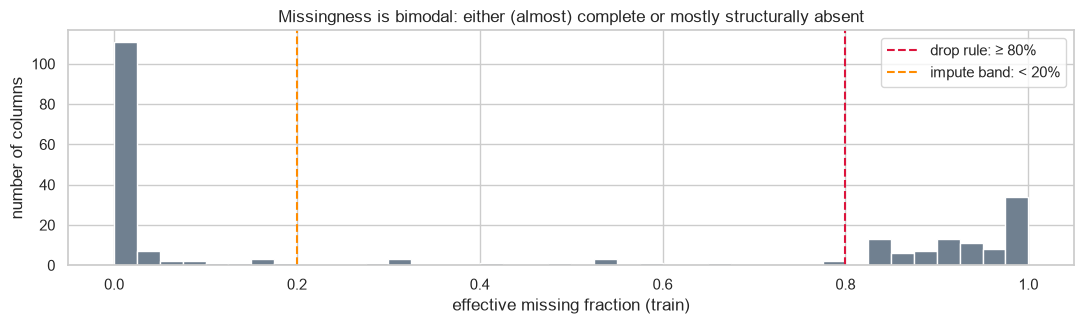

In [32]:
ORIG_COLS = list(raw.columns)                      # 233 original questionnaire columns, in questionnaire order
pos_in_q = {c: i for i, c in enumerate(ORIG_COLS)}
raw_lab  = raw.loc[lab].reset_index(drop=True)
miss_naive_tr = raw_lab.iloc[idx["train"]][ORIG_COLS].isna().mean()          # blanks in the file as delivered
miss_eff_tr   = Xtr_raw[ORIG_COLS].isna().mean()                             # after cleaning (DK codes, '.' placeholders ...)
print(f"columns with >= 80% missing: file as delivered = {(miss_naive_tr >= .8).sum()},  after cleaning (effective) = {(miss_eff_tr >= .8).sum()}")
print(f"columns with 20-80% missing: {((miss_eff_tr >= .2) & (miss_eff_tr < .8)).sum()}   |   0 < missing < 20%: {((miss_eff_tr > 0) & (miss_eff_tr < .2)).sum()}   |   complete: {(miss_eff_tr == 0).sum()}")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.hist(miss_eff_tr, bins=40, color="slategray"); ax.axvline(.8, color="crimson", ls="--", label="drop rule: ≥ 80%"); ax.axvline(.2, color="darkorange", ls="--", label="impute band: < 20%")
ax.set_xlabel("effective missing fraction (train)"); ax.set_ylabel("number of columns"); ax.set_title("Missingness is bimodal: either (almost) complete or mostly structurally absent"); ax.legend(); plt.tight_layout(); plt.show()

In [33]:
pos_in_q["Female"] = pos_in_q["C1_Sex"]; pos_in_q["Urban"] = pos_in_q["X2a_Residence_Rural1_Urban2"]   # derived columns inherit questionnaire position

def gateway_search(W, targets, allow_nan_bucket=False, candidates=None, max_card=15, tol=0.005):
    """For each target column find an EARLIER questionnaire item g and value set S such that 'target is blank <=> g in S'.
    Among near-equally good gateways (within `tol` accuracy) we report the one that is itself least missing, i.e. the most
    fundamental gate rather than a sibling follow-up that is blank for the same reason.
    Output: rule accuracy, baseline (always predict the majority), share of the target's blanks the rule explains, and
    error-reduction = fraction of the baseline's mistakes that the rule removes."""
    cand = candidates if candidates is not None else list(W.columns)
    cand = [c for c in cand if c in pos_in_q and c not in ID_COLS + DESIGN and W[c].nunique(dropna=True) <= max_card]
    fac = {g: pd.factorize(W[g]) for g in cand}                               # code -1 = NaN
    codes = {g: f[0] + 1 for g, f in fac.items()}                            # 0 = NaN bucket
    gmiss = {g: W[g].isna().mean() for g in cand}
    out = []
    for c in targets:
        a = W[c].isna().to_numpy().astype(float); base = max(a.mean(), 1 - a.mean()); found = []
        for g in cand:
            if g == c or pos_in_q[g] >= pos_in_q[c]: continue
            cd = codes[g]; n_v = np.bincount(cd, minlength=cd.max() + 1); na_v = np.bincount(cd, weights=a, minlength=cd.max() + 1)
            S = (na_v > 0.5 * np.maximum(n_v, 1)) & (n_v > 0)
            if not allow_nan_bucket: S[0] = False
            if not S.any(): continue
            pred = S[cd]; acc = float((pred == (a == 1)).mean()); rec = float(pred[a == 1].mean()) if a.sum() else np.nan
            found.append((acc, gmiss[g], pos_in_q[g], g, rec, [("blank" if k == 0 else fac[g][1][k - 1]) for k in np.where(S)[0]]))
        if found:
            top = max(f[0] for f in found); ok = [f for f in found if f[0] >= top - tol]
            acc, _, _, g, rec, S = min(ok, key=lambda f: (f[1], f[2]))
            best = dict(gateway=g, acc=acc, recall=rec, S=S)
        else: best = dict(gateway=None, acc=np.nan, recall=np.nan, S=[])
        out.append(dict(column=c, miss=a.mean(), baseline=base, **best))
    r = pd.DataFrame(out).set_index("column")
    r["error_reduction"] = (r["acc"] - r["baseline"]) / (1 - r["baseline"]).clip(lower=1e-9)
    r["structural"] = (r["acc"] >= 0.97) & (r["recall"] >= 0.90) & (r["error_reduction"] >= 0.5)
    return r

drop80_cols = miss_eff_tr[miss_eff_tr >= 0.80].sort_values(ascending=False).index.tolist()
gw80 = gateway_search(Xtr_raw[ORIG_COLS], drop80_cols, allow_nan_bucket=True)
gw80["section"] = [SECTION[c] for c in gw80.index]; gw80["naive_miss"] = miss_naive_tr[gw80.index]
gw80["why_blank"] = np.where(gw80.structural, "skip logic (gateway rule holds)",
                     np.where(gw80.miss >= 0.99, "near-empty: ≥ 99% blank (follow-up applies to < 1% of people)",
                              "skip logic, two-step gate (per-week item asked only when per-day item not used)"))
print(f"{len(drop80_cols)} columns have >= 80% effective missingness in the training set.")
print(gw80["why_blank"].value_counts().to_string()); print()
print(f"Of these, {int(gw80['structural'].sum())} are explained by an earlier gateway question (blank -> gateway in S with accuracy ≥ 97%, ≥ 90% of blanks explained, and at least half of the baseline's errors removed).")
view = gw80[["section", "naive_miss", "miss", "gateway", "S", "acc", "recall", "error_reduction", "structural"]].copy()
view.columns = ["section", "blank_in_file", "effective_missing", "gateway (earlier item)", "blank when gateway is…", "rule_accuracy", "blanks_explained", "error_reduction", "rule_holds"]
view["why_blank"] = gw80["why_blank"]
display(view.drop(columns=["rule_holds"]).round(3))

92 columns have >= 80% effective missingness in the training set.
why_blank
skip logic (gateway rule holds)                                                    78
near-empty: ≥ 99% blank (follow-up applies to < 1% of people)                      12
skip logic, two-step gate (per-week item asked only when per-day item not used)     2

Of these, 78 are explained by an earlier gateway question (blank -> gateway in S with accuracy ≥ 97%, ≥ 90% of blanks explained, and at least half of the baseline's errors removed).


,section,blank_in_file,effective_missing,gateway (earlier item),blank when gateway is…,rule_accuracy,blanks_explained,error_reduction,why_blank
column,,,,,,,,,
T4b_Months_Since_Started,Tobacco_Smoking,0.998,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
T4c_Weeks_Since_Started,Tobacco_Smoking,0.998,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
T11c_Weeks_Since_Stopped,Tobacco_Smoking,0.999,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
T11b_Months_Since_Stopped,Tobacco_Smoking,0.998,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
T11a_Years_Since_Stopped,Tobacco_Smoking,0.998,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
T14other_Other_Smokeless_Specify,Tobacco_Smokeless,0.000,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
V12other_Violent_Injury_Cause_Specify,Violence,0.000,1.000,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",1.000,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
T4a_Years_Since_Started,Tobacco_Smoking,0.996,0.999,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",0.999,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)
D12other_Oil_Specify,Diet_Salt_Fat,0.000,0.999,X2a_Residence_Rural1_Urban2,"[1.0, 2.0]",0.999,1.000,0.000,near-empty: ≥ 99% blank (follow-up applies to < 1% of people)


### 6.1 Why these columns are missing
Every block of dropped columns is a **conditional follow-up** whose gateway is retained as a feature, so *the information that mattered is not lost; only the sparse detail is*:

| Dropped block | Why blank (skip logic) | Information kept through… |
|---|---|---|
| Smoking detail (T2–T11, T5a–T5fw) | asked only if **T1 = currently smokes** (≈ 9% of people) or if smoked in the past (T8) | `T1` current smoker; `T8` former smoker |
| Smokeless-tobacco detail (T13–T16, T14*) | asked only if **T12 = currently uses smokeless** | `T12` |
| Alcohol detail (A3, A6–A12) | asked only if the person drank in the last 12 months / 30 days (A2 → A5 chain) | `A1`, `A2` (and `A4`/`A5` if they pass the rule) |
| Injury / violence detail (V4, V6, V7, V12, V13) | asked only if a crash, injury or violent incident was reported (V3, V5, V11) | the incident screening items |
| Recreation detail (P11–P12, P14–P15) | asked only if **P10 / P13 = does vigorous / moderate recreation** | `P10`, `P13` |
| BP, cholesterol and diabetes sub-questions (H2b–H5, H7*–H11, H13*–H16) | asked only if the person *was told* they have the condition | the "ever measured" gateways (some excluded for leakage, section 7) |
| Dentures (O5a/b) | asked only if **O4 = wears removable dentures** | `O4` |

**Missingness mechanism.** For all of these the mechanism is **structural / "not applicable"**, i.e. *missing by design*, determined entirely by an observed variable (the gateway). It is therefore *not* MNAR: no hidden quantity drives it. Imputing a value (mean, KNN, MICE) would invent smoking intensity for non-smokers, which is meaningless. **Dropping these columns was judged the right call**, since each column is blank for ≥ 80% of respondents, 80%+ of every cell would be fabricated, and the gateway already carries the signal. This also removed ~11 text "specify" columns that are 99.6–99.9% placeholders `"."`.

In [34]:
full_eff = clean[ORIG_COLS].isna().mean()
near = pd.DataFrame({"train_eff_missing": miss_eff_tr, "full_sample_eff_missing": full_eff})
near["decision_train"] = np.where(near.train_eff_missing >= .8, "DROP", "keep")
near["decision_if_full_sample"] = np.where(near.full_sample_eff_missing >= .8, "DROP", "keep")
flip = near[near.decision_train != near.decision_if_full_sample]
print("columns within ±3 points of the 80% threshold (train):")
display(near[(near.train_eff_missing.between(.77, .83))].round(3))
print("columns whose decision would CHANGE if the full sample had been used:", list(flip.index) if len(flip) else "none")
DROP80 = list(drop80_cols)

columns within ±3 points of the 80% threshold (train):


,train_eff_missing,full_sample_eff_missing,decision_train,decision_if_full_sample
A4_Drinking_Frequency_Past12M,0.783,0.792,keep,keep
A5_Consumed_Past30D,0.783,0.792,keep,keep


columns whose decision would CHANGE if the full sample had been used: none


## 7. Leakage control 
**Target leakage** = a feature that contains, is computed from, or is a *consequence of* the label, so the model "predicts" diabetes by reading its answer. The test for each column is a question about *time and causation*: **would this information exist, and be independent of the diagnosis, when the screening tool is actually used?** Applied to all 233 columns, that test gave:

| Tier | Columns | Verdict and reason |
|---|---|---|
| **A. Label-defining** | `B5` fasting glucose, `B6` diabetes medication today, `B1` fasted flag, `H8` diabetes medication (2 weeks), `H9` insulin | **Excluded.** The label *is* computed from these. Including glucose would give AUC ≈ 1.0 and a useless model. |
| **B. Diagnosis pathway** | `H6`–`H11` (ever had sugar measured, ever told diabetic, treatment, healer/herbal remedy) | **Excluded.** They record *having already been diagnosed*, a downstream consequence of the outcome. A screening tool exists to find people who do **not** know. |
| **C. Post-contact counselling** | `H20a`–`H20h` ("a doctor advised you to reduce sugar / lose weight / exercise…") | **Excluded.** This advice is typically *given because* of a diagnosis (reverse causation) and would not exist for an undiagnosed person. |
| **D. Same-visit laboratory block** | `B2`–`B4`, `B8`/`B17` cholesterol, `B9` | **Excluded.** Drawn in the same blood draw as the label (not a cheap screen), plus technician, meter and specimen-time identifiers that can encode batch effects. |
| **E. Identifiers & design** | participant ID, interviewer / device IDs (`M1`, `M2`, `M10ab`, `M13`), `PSU_Cluster`, `Stratum`, survey weights, derived age range | **Excluded as features.** IDs and PSU let a model memorise places and field teams; weights are sampling artefacts; age range duplicates age. PSU was used *only* as the grouping key of the split; weights were used *only* for a robustness check. |
| **F. Legitimate predictors that were kept and flagged** | `H1`–`H5` (BP history), `H12`–`H19` (cholesterol history, heart disease, aspirin, statins) | **Kept, flagged.** They are comorbidity history a health worker can ask about, but they correlate with health-service contact. Section 14 measures how much they matter. |

Nothing about the validation/test rows was used to build the pipeline.

In [35]:
def C(*codes): return [col(c) for c in codes]
LEAK_GROUPS = {
    "A. label-defining":             C("B5", "B6", "B1", "H8", "H9"),
    "B. diagnosis pathway":          C("H6", "H7a", "H7b", "H10", "H11"),
    "C. post-contact counselling":   C("H20a", "H20b", "H20c", "H20d", "H20e", "H20f", "H20g", "H20h"),
    "D. same-visit laboratory":      [c for c in STEP3 if c not in C("B5", "B6", "B1")],
    "E. identifiers & survey design": ID_COLS + DESIGN,
}
LEAK_COLS = sorted({c for v in LEAK_GROUPS.values() for c in v}, key=pos_in_q.get)
CONSUMED = (C("C3", "C1", "X2a") + C("M4a", "M4b", "M5a", "M5b", "M6a", "M6b", "M16a", "M16b", "M16c", "M11", "M12", "M14", "M15")
            + C("P2", "P3a", "P3b", "P5", "P6a", "P6b", "P8", "P9a", "P9b", "P16a", "P16b", "D1", "D2", "D3", "D4"))  # raw items turned into engineered features (section 8)

fate = {}
for c in ORIG_COLS:
    if c in DROP80:                     fate[c] = "dropped: ≥ 80% missing"
    elif c in LEAK_GROUPS["A. label-defining"]:  fate[c] = "excluded: A label-defining"
    elif c in LEAK_GROUPS["B. diagnosis pathway"]: fate[c] = "excluded: B diagnosis pathway"
    elif c in LEAK_GROUPS["C. post-contact counselling"]: fate[c] = "excluded: C post-contact counselling"
    elif c in LEAK_GROUPS["D. same-visit laboratory"]: fate[c] = "excluded: D same-visit laboratory"
    elif c in LEAK_GROUPS["E. identifiers & survey design"]: fate[c] = "excluded: E identifiers / survey design"
    elif c in CONSUMED:                 fate[c] = "kept (as engineered feature)"
    else:                               fate[c] = "kept (as is)"
fate = pd.Series(fate)
print("Accounting for all", len(fate), "original columns (priority: ≥80%-missing rule first, then leakage tiers):")
display(fate.value_counts().rename("n_columns").to_frame())
also = [c for c in DROP80 if c in LEAK_COLS]
print(f"{len(also)} of the {len(DROP80)} high-missing columns would ALSO have been excluded for leakage (e.g. {[a.split('_')[0] for a in also][:12]}).")

# univariate evidence on the TRAIN set only: how strongly does each excluded column "know" the label?
def uni_auc(s, yy):
    m = s.notna()
    if m.sum() < 30 or yy[m].nunique() < 2: return np.nan
    a = roc_auc_score(yy[m], s[m]); return max(a, 1 - a)
evid = []
for grp_name, cols_ in LEAK_GROUPS.items():
    for c in cols_:
        if pd.api.types.is_numeric_dtype(Xtr_raw[c]) and c not in DESIGN + ID_COLS:
            evid.append((grp_name, c, Xtr_raw[c].notna().mean(), uni_auc(Xtr_raw[c], ytr)))
evid = pd.DataFrame(evid, columns=["tier", "column", "share_observed", "univariate_AUC_train"]).sort_values("univariate_AUC_train", ascending=False)
print("Excluded columns ranked by univariate AUC against the label (train). Values near 1.0 have a high tale of leakage; sparse columns are high only because very few people answer them:")
display(evid.head(12).round(3))

Accounting for all 233 original columns (priority: ≥80%-missing rule first, then leakage tiers):


,n_columns
dropped: ≥ 80% missing,92
kept (as is),80
kept (as engineered feature),31
excluded: E identifiers / survey design,11
excluded: C post-contact counselling,8
excluded: D same-visit laboratory,7
excluded: A label-defining,3
excluded: B diagnosis pathway,1


6 of the 92 high-missing columns would ALSO have been excluded for leakage (e.g. ['H8', 'H7b', 'H11', 'H9', 'H10', 'H7a']).
Excluded columns ranked by univariate AUC against the label (train). Values near 1.0 have a high tale of leakage; sparse columns are high only because very few people answer them:


,tier,column,share_observed,univariate_AUC_train
0,A. label-defining,B5_Fasting_Glucose_mmol_L,1.000,0.946
3,A. label-defining,H8_Diabetes_Medication_Past2W,0.017,0.938
6,B. diagnosis pathway,H7a_Ever_Told_Diabetes,0.155,0.826
7,B. diagnosis pathway,H7b_Told_Diabetes_Past12M,0.017,0.778
4,A. label-defining,H9_Taking_Insulin,0.018,0.734
5,B. diagnosis pathway,H6_Blood_Sugar_Ever_Measured,1.000,0.712
20,D. same-visit laboratory,B8csv_Total_Cholesterol_mmol_L_QuestionnaireB7,0.999,0.667
13,C. post-contact counselling,H20d_Advised_Reduce_Sugar,1.000,0.622
15,C. post-contact counselling,H20f_Advised_Reduce_Fat,1.000,0.599
12,C. post-contact counselling,H20c_Advised_Reduce_Salt,1.000,0.592


## 8. Missing values in the columns kept (structural fills, imputation plan and feature engineering)
After the 80% rule and the leakage exclusions, the surviving columns still contained blanks. They were handled on the principle that the right method depends on **why** the value is blank. The surviving blanks were therefore split into two kinds, learned from the **training set only**:

1. **Structural blanks (skip logic) in the 20–80% band and a few smaller ones** (e.g. "servings of fruit per day" is blank for people who eat fruit 0 days a week). *Statistical imputation would have been wrong*: the true value is not unknown, it is **undefined or zero**. A **logical (rule-based) fill** was applied instead: quantities (days, hours, servings) → `0`; categorical follow-ups (e.g. "ever told you have raised BP?" for someone never measured) → an explicit level **`not_applicable`**. The gateway was retained, so no information was lost and no value was invented. *(No treatment was prescribed for the 20–80% band; logical filling was adopted as the justified default, and statistical imputation remains a legitimate alternative.)*
2. **Genuine blanks (< 20%)**: refusals / "don't know" and failed measurements. These were the columns to impute, according to the following plan:

| Mechanism | Evidence we can show | Treatment |
|---|---|---|
| **MCAR, < 5%** | blank rate unrelated to age/sex/residence | median (numeric) / mode (categorical) |
| **MAR, moderate (5–20%)** or MAR measurement block | blank rate predictable from observed age, sex, residence | **multivariate imputation (MICE-style `IterativeImputer`)** using correlated measurements |
| **MNAR-suspect** ("don't know" answers) | blanks created from DK/refused codes; cannot be tested from data by definition | **simple imputation + a missing-indicator column**, so the model can use "didn't know" as a signal |
| Tree models | LightGBM routes NaN natively | **no imputation** for LightGBM numerics; indicators implicit |

**Every fitted quantity (medians, modes, regression coefficients of the iterative imputer, category lists) lived inside a scikit-learn `Pipeline`/`ColumnTransformer`, so cross-validation refitted it inside each fold.**

In [36]:
UNIVERSE = [c for c in ORIG_COLS if fate[c].startswith("kept")]
QTY = re.compile(r"(_Days|Days_|Hours|Minutes|Servings|Per_Day|Per_Week|Meals)")
W0 = Xtr_raw[UNIVERSE + ["Female", "Urban"]].copy()                     # train rows, cleaned, in questionnaire order

def derive_structural_rules(W, cols, verbose=False):
    W, rules = W.copy(), {}
    for c in cols:
        if W[c].isna().sum() == 0: continue
        r = gateway_search(W, [c], allow_nan_bucket=False, candidates=[g for g in W.columns if g != c]).iloc[0]
        if r["structural"]:
            kind = "zero" if QTY.search(c) else "level"
            m = W[c].isna() & W[r["gateway"]].isin(r["S"])
            W.loc[m, c] = 0.0 if kind == "zero" else -1.0
            rules[c] = (r["gateway"], list(r["S"]), kind)
    return W, rules

W1, STRUCT_RULES = derive_structural_rules(W0, [c for c in UNIVERSE if c in W0.columns])
rule_tab = pd.DataFrame([(c, g, S, k, W0[c].isna().mean(), W1[c].isna().mean()) for c, (g, S, k) in STRUCT_RULES.items()],
                        columns=["column", "gateway", "blank_when_gateway_in", "fill", "missing_before", "missing_after"]).set_index("column")
print(f"{len(rule_tab)} kept columns have blanks that are pure skip logic and receive a deterministic fill (learned on train):")
display(rule_tab.sort_values("missing_before", ascending=False).round(3))

resid = W1.isna().mean(); resid = resid[resid > 0].sort_values(ascending=False)
print(f"After the logical fills, {len(resid)} columns still contain genuine blanks. Worst case = {resid.max():.1%}  (all < 20%, so the 'impute under 20%' rule applies to every one).")

28 kept columns have blanks that are pure skip logic and receive a deterministic fill (learned on train):


,gateway,blank_when_gateway_in,fill,missing_before,missing_after
column,,,,,
A4_Drinking_Frequency_Past12M,A2_Consumed_Past12M,"[-1.0, 0.0]",level,0.783,0.000
A5_Consumed_Past30D,A2_Consumed_Past12M,"[-1.0, 0.0]",level,0.783,0.000
A2_Consumed_Past12M,A1_Ever_Consumed_Alcohol,[0.0],level,0.663,0.000
O8_Reason_Last_Dentist_Visit,O7_Time_Since_Last_Dentist,[6.0],level,0.578,0.000
P3b_Vigorous_Work_Minutes,P1_Vigorous_Work,[0.0],zero,0.548,0.001
P3a_Vigorous_Work_Hours,P1_Vigorous_Work,[0.0],zero,0.548,0.001
P2_Vigorous_Work_Days,P1_Vigorous_Work,[0.0],zero,0.547,0.000
H2a_Ever_Told_Raised_BP,H1_BP_Ever_Measured,[0.0],level,0.499,0.000
CX1_Ever_Screened_Women_Only,C1_Sex,[Men],level,0.406,0.001


After the logical fills, 54 columns still contain genuine blanks. Worst case = 14.2%  (all < 20%, so the 'impute under 20%' rule applies to every one).


### 8.1 Evidence about the *mechanism* of the genuine blanks (train only)
MNAR cannot be proven from data (the missing value is, by definition, unobserved), but **MAR** can be shown: if the blank pattern is predictable from fully observed covariates (age, sex, residence, schooling), it is not MCAR. For every column with ≥ 20 blanks we fitted a small logistic regression `P(blank | age, female, urban, schooling)` and reported the grouped cross-validated AUC (0.5 = MCAR-compatible; > 0.6 = clear MAR). We also counted how many of the blanks were created from "don't know/refused" codes (a hint of MNAR).

In [37]:
from sklearn.model_selection import GroupKFold
cov = W1[["C3_Age_Years", "Female", "Urban", "C4_Years_Of_Schooling"]].copy(); cov["C4_Years_Of_Schooling"] = cov["C4_Years_Of_Schooling"].fillna(cov["C4_Years_Of_Schooling"].median())
dk_counts = CLEAN_LOG[CLEAN_LOG.rule.str.contains("sentinel|don't-know")].groupby("column")["n_cells"].sum()   # blanks created from DK / refused codes only
rows = []
for c in resid.index:
    a = W1[c].isna().astype(int).to_numpy()
    if a.sum() < 20: continue
    aucs = []
    for tr_i, te_i in GroupKFold(5).split(cov, a, gtr):
        if a[tr_i].sum() < 3 or a[te_i].sum() < 1: continue
        m = Pipeline([("s", StandardScaler()), ("lr", LogisticRegression(max_iter=500))]).fit(cov.iloc[tr_i], a[tr_i])
        aucs.append(roc_auc_score(a[te_i], m.predict_proba(cov.iloc[te_i])[:, 1]))
    auc = np.mean(aucs) if aucs else np.nan
    dk_share = min(1.0, dk_counts.get(c, 0) / max(a.sum(), 1))
    rows.append((c, SECTION[c], a.mean(), int(a.sum()), auc, dk_share))
mech = pd.DataFrame(rows, columns=["column", "section", "missing", "n_blank", "AUC_blank_vs_age_sex_urban_school", "share_blanks_from_DK_codes"]).set_index("column")
mech["mechanism_verdict"] = np.select(
    [mech.share_blanks_from_DK_codes >= 0.5, mech.AUC_blank_vs_age_sex_urban_school >= 0.60],
    ["MNAR-suspect ('don't know'/refused)", "MAR (blank rate depends on age/sex/residence/education)"], default="MCAR-compatible (no covariate signal)")
mech["treatment"] = np.select(
    [mech.section.str.startswith("Step2"), mech.mechanism_verdict.str.startswith("MNAR"), mech.mechanism_verdict.str.startswith("MAR")],
    ["MICE-style IterativeImputer (measurement block)", "mode/median + missing-indicator", "median/mode (+ indicator)"], default="median/mode")
display(mech.sort_values("missing", ascending=False).round(3))
print(mech.mechanism_verdict.value_counts().to_string())

# co-missingness of the Step-2 body measurements: they fail together (a respondent who skipped Step 2 lacks all of them)
s2 = [col("M4a"), col("M5a"), col("M11"), col("M12"), col("M14"), col("M15")]
print("\nShare of respondents missing ALL six core Step-2 measurements:", f"{W1[s2].isna().all(axis=1).mean():.2%}",
      "| missing at least one:", f"{W1[s2].isna().any(axis=1).mean():.2%}")
print("=> Step-2 blanks are mostly 'did not attend / device failure', which is a process failure rather than a person-level value: MAR/MCAR, handled with a joint iterative imputer plus a single 'step2_incomplete' flag.")

,section,missing,n_blank,AUC_blank_vs_age_sex_urban_school,share_blanks_from_DK_codes,mechanism_verdict,treatment
column,,,,,,,
V10_Rode_With_Drinking_Driver_Past30D,Unintentional_Injury,0.142,406,0.530,1.000,MNAR-suspect ('don't know'/refused),mode/median + missing-indicator
D10_Salt_Causes_Health_Problem,Diet_Salt_Fat,0.119,341,0.650,1.000,MNAR-suspect ('don't know'/refused),mode/median + missing-indicator
D9_Importance_Of_Lowering_Salt,Diet_Salt_Fat,0.089,255,0.670,1.000,MNAR-suspect ('don't know'/refused),mode/median + missing-indicator
M14_Waist_cm,Step2_Height_Weight,0.065,186,0.687,0.000,MAR (blank rate depends on age/sex/residence/education),MICE-style IterativeImputer (measurement block)
M15_Hip_cm,Step2_Height_Weight,0.061,173,0.687,0.000,MAR (blank rate depends on age/sex/residence/education),MICE-style IterativeImputer (measurement block)
M11_Height_cm,Step2_Height_Weight,0.039,111,0.739,0.000,MAR (blank rate depends on age/sex/residence/education),MICE-style IterativeImputer (measurement block)
M12_Weight_kg,Step2_Height_Weight,0.039,110,0.741,0.000,MAR (blank rate depends on age/sex/residence/education),MICE-style IterativeImputer (measurement block)
V9_Drove_After_2Plus_Drinks_Past30D,Unintentional_Injury,0.031,88,0.559,1.000,MNAR-suspect ('don't know'/refused),mode/median + missing-indicator
D8_Perceived_Salt_Intake,Diet_Salt_Fat,0.018,51,0.580,1.000,MNAR-suspect ('don't know'/refused),mode/median + missing-indicator


mechanism_verdict
MNAR-suspect ('don't know'/refused)                        14
MAR (blank rate depends on age/sex/residence/education)     5

Share of respondents missing ALL six core Step-2 measurements: 0.42% | missing at least one: 7.00%
=> Step-2 blanks are mostly 'did not attend / device failure', which is a process failure rather than a person-level value: MAR/MCAR, handled with a joint iterative imputer plus a single 'step2_incomplete' flag.


### 8.2 Feature engineering (deterministic, row-wise, therefore leak-free)
Raw items are replaced by clinically meaningful composites. This reduced ~60 noisy columns to ~15 strong ones, which mattered because only **81 positive training cases** were available (the events-per-variable ratio is the binding constraint on a logistic model).

| New feature | Built from | Why |
|---|---|---|
| `bmi` | weight / height² | standard adiposity index; the dominant modifiable diabetes risk factor |
| `waist`, `whr` | waist, waist / hip | central adiposity predicts insulin resistance better than BMI |
| `sbp`, `dbp`, `hr`, `pulse_pressure` | mean of BP readings 2 and 3 (STEPS protocol: reading 1 is discarded because of "white-coat" alerting; reading 1 is used only if both are missing) | averaging reduces measurement noise; pulse pressure = arterial stiffness |
| `step2_incomplete` | any of BMI/waist/BP missing | keeps the information that the physical examination failed (MNAR guard) |
| `met_min_week` | WHO GPAQ: 8 × vigorous-work min + 4 × (moderate-work + travel min) | one physical-activity number instead of 9 |
| `sitting_min_day` | hours × 60 + minutes | sedentary time |
| `fruit_veg_servings_day` | (fruit days × servings + vegetable days × servings) / 7 | WHO "5-a-day" metric |
| `age`, `female`, `urban`, `schooling_years` | demographics | classical risk factors / socio-economic context |

Note that the activity composites used only items that survived the 80% rule (recreation durations were dropped; the yes/no recreation gateways `P10`, `P13` remain).

In [38]:
ENG_MEAS = ["age", "bmi", "waist", "whr", "sbp", "dbp", "hr", "pulse_pressure", "female", "urban"]   # measurement block (imputed jointly)
ORD_COLS = C("D5", "D6", "D7", "D8", "D9", "O1")                                                         # ordered response scales

def apply_structural(d, rules):
    d = d.copy()
    for c, (g, S, kind) in rules.items():                       # rules are stored in questionnaire order => chains resolve correctly
        m = d[c].isna() & d[g].isin(S)
        d.loc[m, c] = 0.0 if kind == "zero" else -1.0
    return d

def build_features(df_clean):
    d = apply_structural(df_clean[UNIVERSE + ["Female", "Urban"]], STRUCT_RULES)
    f = pd.DataFrame(index=d.index)
    f["age"], f["female"], f["urban"], f["schooling_years"] = d["C3_Age_Years"], d["Female"], d["Urban"], d["C4_Years_Of_Schooling"]
    h, w, wa, hi = d[col("M11")], d[col("M12")], d[col("M14")], d[col("M15")]
    f["bmi"] = (w / (h / 100) ** 2).where(lambda s: s.between(12, 70)); f["waist"] = wa; f["whr"] = (wa / hi).where(lambda s: s.between(0.5, 1.5))
    f["sbp"] = d[C("M5a", "M6a")].mean(axis=1).fillna(d[col("M4a")]); f["dbp"] = d[C("M5b", "M6b")].mean(axis=1).fillna(d[col("M4b")])
    f["hr"] = d[C("M16a", "M16b", "M16c")].mean(axis=1); f["pulse_pressure"] = f["sbp"] - f["dbp"]
    f["step2_incomplete"] = f[["bmi", "waist", "whr", "sbp", "dbp"]].isna().any(axis=1).astype(float)
    mins = lambda hc, mc: d[col(hc)] * 60 + d[col(mc)]
    vig, mod, trv = d[col("P2")] * mins("P3a", "P3b"), d[col("P5")] * mins("P6a", "P6b"), d[col("P8")] * mins("P9a", "P9b")
    f["met_min_week"] = 8 * vig + 4 * (mod + trv); f["sitting_min_day"] = mins("P16a", "P16b")
    f["fruit_veg_servings_day"] = (d[col("D1")] * d[col("D2")] + d[col("D3")] * d[col("D4")]) / 7
    for c in UNIVERSE:
        if c not in CONSUMED: f[c] = d[c]
    return f

F0 = build_features(Xtr_raw)
LEVEL_COLS = [c for c, (_, _, k) in STRUCT_RULES.items() if k == "level" and c in F0.columns]
OBJ_COLS   = [c for c in F0.columns if not pd.api.types.is_numeric_dtype(F0[c])]
CAT_NUM    = [c for c in F0.columns if c not in LEVEL_COLS + OBJ_COLS + ENG_MEAS + ORD_COLS
              and not set(F0[c].dropna().unique()) <= {0.0, 1.0} and F0[c].nunique() <= 10]
BIN_F      = [c for c in F0.columns if c not in LEVEL_COLS + OBJ_COLS + CAT_NUM + ENG_MEAS + ORD_COLS and set(F0[c].dropna().unique()) <= {0.0, 1.0}]
NUM_F      = [c for c in F0.columns if c not in LEVEL_COLS + OBJ_COLS + CAT_NUM + ENG_MEAS + ORD_COLS + BIN_F]
CAT_F      = LEVEL_COLS + OBJ_COLS + CAT_NUM

def finalize(f):
    f = f.copy()
    for c in LEVEL_COLS:
        isbin = c in BIN_COLS
        f[c] = f[c].map(lambda v: np.nan if pd.isna(v) else ("not_applicable" if v == -1 else (("yes" if v == 1 else "no") if isbin else str(int(v)))))
    for c in CAT_NUM: f[c] = f[c].map(lambda v: np.nan if pd.isna(v) else str(int(v)))
    for c in OBJ_COLS: f[c] = f[c].astype(object).where(f[c].notna(), np.nan)
    return f

Ftr, Fva, Fte = (finalize(build_features(X)) for X in (Xtr_raw, Xva_raw, Xte_raw))
assert list(Ftr.columns) == list(Fva.columns) == list(Fte.columns)
FEATURES = list(Ftr.columns)
FORBIDDEN = set(LEAK_COLS) | set(DROP80) | set(ID_COLS + DESIGN)
assert not (set(FEATURES) & FORBIDDEN), set(FEATURES) & FORBIDDEN
print(f"{len(FEATURES)} model input features: {len(ENG_MEAS)} measurement-block, {len(NUM_F)} numeric/quantity, {len(ORD_COLS)} ordinal, {len(BIN_F)} yes/no (incl. the step2_incomplete flag), {len(CAT_F)} categorical")
types_tab = pd.Series({**{c: "measurement (joint imputation)" for c in ENG_MEAS}, **{c: "numeric / quantity" for c in NUM_F},
                       **{c: "ordinal scale" for c in ORD_COLS}, **{c: "yes/no" for c in BIN_F},
                       **{c: "categorical (one-hot)" for c in CAT_F}}).reindex(FEATURES)
display(types_tab.value_counts().rename("n").to_frame().T)
print("train missing after structural fills (columns with any), top 12:"); display(Ftr.isna().mean()[lambda s: s > 0].sort_values(ascending=False).head(12).round(3).to_frame("missing"))

95 model input features: 10 measurement-block, 8 numeric/quantity, 6 ordinal, 38 yes/no (incl. the step2_incomplete flag), 33 categorical


,yes/no,categorical (one-hot),measurement (joint imputation),numeric / quantity,ordinal scale
n,38,33,10,8,6


train missing after structural fills (columns with any), top 12:


,missing
V10_Rode_With_Drinking_Driver_Past30D,0.142
D10_Salt_Causes_Health_Problem,0.119
D9_Importance_Of_Lowering_Salt,0.089
whr,0.067
waist,0.065
bmi,0.041
V9_Drove_After_2Plus_Drinks_Past30D,0.031
met_min_week,0.020
D8_Perceived_Salt_Intake,0.018
O11_Fluoride_Toothpaste,0.016


## 9. Per-model preprocessing (the "necessary transformations for each model")
Different learners make different assumptions, so each received only the transformations it needs. All are `scikit-learn` pipelines, **fitted on the training rows only** and applied unchanged to validation and test.

| Step | Elastic-net logistic regression | Random forest | LightGBM | Reason |
|---|---|---|---|---|
| Measurement block (age, BMI, waist, WHR, BP, HR…) | `IterativeImputer` (MICE-style, BayesianRidge) → standardise | `IterativeImputer` | **left as NaN** (native handling) | MAR block of correlated variables; a linear model needs scaled inputs, trees do not |
| Skewed quantities (activity minutes, sitting, servings, schooling) | median impute → **Yeo-Johnson** → standardise; + missing-indicators | median impute; + indicators | NaN native | Penalised linear models are scale- and skew-sensitive; trees are invariant to monotone transforms |
| Ordinal scales | mode impute → standardise; + indicators | mode impute; + indicators | NaN native | |
| Yes/no items | mode impute; + indicators | mode impute; + indicators | NaN native | "don't know" is kept visible through the indicator (MNAR guard) |
| Categorical (education, ethnicity, marital status, oil type, structural "not_applicable" levels…) | `unknown` level → **one-hot** (rare levels < 1% pooled) | same | same | no ordering is implied; pooling stops 1-person levels from creating noise |
| Class imbalance (2.8% positives) | `class_weight` tuned | `class_weight` tuned | `scale_pos_weight` tuned | *weights in the loss, not SMOTE*: SMOTE would interpolate between 81 positives in a 250-dimensional space that mixes binary and categorical columns, and it distorts probabilities; weighting kept the data real and calibration was repaired afterwards (SMOTE, where used at all, is valid only inside the training folds) |
| Feature selection | **elastic-net** (L1 inside the model) | built-in importance | built-in split gain | selection happens *inside* the CV loop, never before it |

In [39]:
from joblib import Memory
CACHE = Memory("diabetes_model/cache", verbose=0)

def make_prep(kind, extra_num=(), extra_bin=()):
    """kind in {'linear','forest','gbm'}; extra_* only used by the leakage ablation in section 14."""
    meas, ord_, cat = ENG_MEAS, ORD_COLS, CAT_F
    num = NUM_F + list(extra_num); bin_all = BIN_F + list(extra_bin)
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                         ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False))])
    mice = lambda: IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=SEED, initial_strategy="median", skip_complete=True)
    if kind == "linear":
        parts = [("meas", Pipeline([("imp", mice()), ("sc", StandardScaler())]), meas),
                 ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("pt", PowerTransformer(method="yeo-johnson", standardize=True))]), num),
                 ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("sc", StandardScaler())]), ord_),
                 ("bin", SimpleImputer(strategy="most_frequent"), bin_all),
                 ("ind", MissingIndicator(features="missing-only", error_on_new=False), num + ord_ + bin_all),
                 ("cat", cat_pipe, cat)]
    elif kind == "forest":
        parts = [("meas", mice(), meas), ("num", SimpleImputer(strategy="median"), num), ("ord", SimpleImputer(strategy="most_frequent"), ord_),
                 ("bin", SimpleImputer(strategy="most_frequent"), bin_all),
                 ("ind", MissingIndicator(features="missing-only", error_on_new=False), num + ord_ + bin_all), ("cat", cat_pipe, cat)]
    elif kind == "gbm":
        parts = [("meas", "passthrough", meas), ("num", "passthrough", num), ("ord", "passthrough", ord_), ("bin", "passthrough", bin_all), ("cat", cat_pipe, cat)]
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=True)

def make_pipe(kind, model): return Pipeline([("prep", make_prep(kind)), ("model", model)], memory=CACHE)

# every column of the frame is assigned to exactly one block (except the ones deliberately duplicated into indicators)
assigned = set(ENG_MEAS + NUM_F + ORD_COLS + BIN_F + CAT_F)
print("unassigned features:", set(FEATURES) - assigned, "| assigned but not in frame:", assigned - set(FEATURES))
_p = make_prep("linear").fit(Ftr, ytr); names_linear = _p.get_feature_names_out()
print("linear design matrix:", _p.transform(Ftr).shape, "| after fitting on train, e.g. 'age' scaler mean =", round(_p.named_transformers_["meas"]["sc"].mean_[0], 4),
      "= train mean", round(Ftr.age.mean(), 4), "(full-sample mean would be", round(Xall["C3_Age_Years"].mean(), 4), ")")

unassigned features: set() | assigned but not in frame: set()
linear design matrix: (2857, 236) | after fitting on train, e.g. 'age' scaler mean = 37.665 = train mean 37.665 (full-sample mean would be 37.4836 )


## 10. Evaluation protocol and baselines
* **Cross-validation (for tuning, train only):** `StratifiedGroupKFold(5)` keeping PSUs together; ~16 positives per fold. Primary tuning metric **PR-AUC (average precision)**, because with 2.8% positives it measures how well positives are ranked at the top, where screening decisions are made; ROC-AUC is reported but is inflated by the many easy negatives.
* **Validation (model comparison, calibration, threshold):** 603 people, 17 positives. Metric uncertainty is therefore large; we reported **PSU-cluster bootstrap 95% intervals** (resampling whole clusters, respecting the survey design) rather than pretending a single number is exact.
* **Baselines to beat:** (i) a prevalence-only dummy (PR-AUC = prevalence ≈ 0.028), (ii) a **clinical logistic regression** with the 8 classic risk variables.

In [40]:
cv_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(Ftr, ytr, gtr))
print("positives per CV fold:", [int(ytr.iloc[te].sum()) for _, te in cv_splits], "| clusters per fold:", [gtr.iloc[te].nunique() for _, te in cv_splits])

def cluster_bootstrap(yv, pv, groups, fn, B=1000, seed=SEED):
    rng = np.random.RandomState(seed); ug = groups.unique(); by = {g: np.where(groups.values == g)[0] for g in ug}; out = []
    for _ in range(B):
        ii = np.concatenate([by[g] for g in rng.choice(ug, len(ug), replace=True)])
        if yv.iloc[ii].nunique() < 2: continue
        out.append(fn(yv.iloc[ii], pv[ii]))
    return np.array(out)

def metrics(yv, pv, groups=None, B=1000):
    r = {"ROC-AUC": roc_auc_score(yv, pv), "PR-AUC": average_precision_score(yv, pv), "Brier": brier_score_loss(yv, pv)}
    if groups is not None:
        for k, fn in {"ROC-AUC": roc_auc_score, "PR-AUC": average_precision_score}.items():
            b = cluster_bootstrap(yv, pv, groups, fn, B); r[k + " 95% CI"] = f"{np.percentile(b, 2.5):.3f}–{np.percentile(b, 97.5):.3f}"; r[k + " SD"] = b.std()
    return r

prev_tr = ytr.mean()
dummy = DummyClassifier(strategy="prior").fit(Ftr, ytr)
clin_cols = ["age", "female", "bmi", "waist", "whr", "sbp", "dbp", "urban"]
clin = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("lr", LogisticRegression(C=1.0, max_iter=1000))]).fit(Ftr[clin_cols], ytr)
res_val = {}
res_val["Dummy (prevalence)"] = metrics(yva, dummy.predict_proba(Fva)[:, 1], gva)
p_clin = clin.predict_proba(Fva[clin_cols])[:, 1]; res_val["Clinical LR (8 risk factors)"] = metrics(yva, p_clin, gva)
display(pd.DataFrame(res_val).T.drop(columns=[c for c in ["ROC-AUC SD", "PR-AUC SD"]]).round(3))

positives per CV fold: [11, 24, 13, 16, 17] | clusters per fold: [29, 28, 27, 28, 28]


,ROC-AUC,PR-AUC,Brier,ROC-AUC 95% CI,PR-AUC 95% CI
Dummy (prevalence),0.5,0.028192,0.027398,0.500–0.500,0.015–0.043
Clinical LR (8 risk factors),0.784782,0.133435,0.026287,0.682–0.886,0.049–0.323


## 11. Choosing the models and tuning them
**Candidate models considered and why**

| Learner | Used? | Reasoning for *this* data (n = 2,857 train, 81 events, ~230 design columns, mixed types, many blanks) |
|---|---|---|
| **Elastic-net logistic regression** | ✅ **Model 1** | A strong, well-understood baseline that any more complex model has to beat. A penalty is essential because events-per-variable ≪ 1; L1 selects, L2 stabilises correlated anthropometrics. Coefficients are auditable by clinicians, scoring is microseconds. |
| **Random forest** | ✅ **Model 2** | Averages many decorrelated deep trees, so variance falls without raising bias; captures non-linear and interaction effects (age × BMI) the linear model cannot; robust to scaling and outliers; `class_weight` handles imbalance. |
| **Gradient-boosted trees, LightGBM** | ✅ **Model 3** | State of the art for tabular data; sequential bias reduction; handles NaN natively (so no imputation assumption for it); `scale_pos_weight`; regularisation knobs (`min_child_samples`, `reg_lambda`, shallow leaves) suit a tiny positive class. Tuned with **Optuna TPE**. |
| Soft-voting ensemble | ✅ extra | Averages the three calibrated probabilities; diverse families reduce variance. Judged on validation like the others. |
| kNN, SVM, naïve Bayes | ❌ | kNN: distance is meaningless in ~230 mixed dimensions; SVM: needs extra calibration, no native probabilities; naïve Bayes: independence is false for collinear BMI/waist/hip/BP. |
| Neural networks, CNN, sequence models, LLMs | ❌ | Need far more data than 81 positives and have no structure to exploit in a flat survey table; gradient-boosted trees remain a standard choice for tabular risk scoring. |

### 11.1 Model 1: elastic-net logistic regression
Tuned by grouped 5-fold CV (train only) over penalty strength `C` (smaller = stronger), mixing `l1_ratio` (0 = ridge, 1 = lasso) and `class_weight` (none vs balanced). Note that in scikit-learn `C = 1/λ`, so larger C means *weaker* regularisation.

In [41]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
t0 = time.time()
lr_pipe = make_pipe("linear", LogisticRegression(solver="saga", max_iter=3000, tol=1e-3, random_state=SEED))
lr_grid = {"model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], "model__l1_ratio": [0.0, 0.5, 1.0], "model__class_weight": [None, "balanced"]}
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="average_precision", cv=cv_splits, n_jobs=2, refit=True).fit(Ftr, ytr)
print(f"best CV PR-AUC = {lr_search.best_score_:.3f}   params = {lr_search.best_params_}   ({time.time()-t0:.0f}s)")
cvr = pd.DataFrame(lr_search.cv_results_)[["param_model__C", "param_model__l1_ratio", "param_model__class_weight", "mean_test_score", "std_test_score"]]
display(cvr.sort_values("mean_test_score", ascending=False).head(8).round(4))
lr_best = lr_search.best_estimator_
coef = pd.Series(lr_best["model"].coef_[0], index=lr_best["prep"].get_feature_names_out())
print(f"non-zero coefficients: {(coef != 0).sum()} of {len(coef)} (elastic-net selected the rest out)")

best CV PR-AUC = 0.182   params = {'model__C': 0.01, 'model__class_weight': None, 'model__l1_ratio': 0.0}   (1672s)


,param_model__C,param_model__l1_ratio,param_model__class_weight,mean_test_score,std_test_score
6,0.010,0.0,None,0.182,0.0467
8,0.010,1.0,None,0.182,0.0467
7,0.010,0.5,None,0.182,0.0467
12,0.030,0.0,None,0.176,0.0547
13,0.030,0.5,None,0.176,0.0547
14,0.030,1.0,None,0.176,0.0547
1,0.003,0.5,None,0.169,0.0514
0,0.003,0.0,None,0.169,0.0514


non-zero coefficients: 236 of 236 (elastic-net selected the rest out)


### 11.2 Model 2: random forest
`RandomizedSearchCV` (20 draws) over tree depth, leaf size, features per split, class weighting and bootstrap size. A larger `min_samples_leaf` and shallower depth are the regularisers that matter with 81 positives (a leaf of 3 people with 1 positive is noise).

In [42]:
t0 = time.time()
rf_pipe = make_pipe("forest", RandomForestClassifier(n_estimators=300, n_jobs=2, random_state=SEED))
rf_dist = {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [3, 5, 10, 20, 40], "model__max_features": ["sqrt", 0.1, 0.25, 0.5],
           "model__class_weight": ["balanced_subsample", None], "model__max_samples": [0.5, 0.8, None]}
rf_search = RandomizedSearchCV(rf_pipe, rf_dist, n_iter=20, scoring="average_precision", cv=cv_splits, n_jobs=1, random_state=SEED, refit=True).fit(Ftr, ytr)
print(f"best CV PR-AUC = {rf_search.best_score_:.3f}   params = {rf_search.best_params_}   ({time.time()-t0:.0f}s)")
rf_best = rf_search.best_estimator_

best CV PR-AUC = 0.165   params = {'model__min_samples_leaf': 40, 'model__max_samples': 0.5, 'model__max_features': 0.5, 'model__max_depth': 5, 'model__class_weight': 'balanced_subsample'}   (266s)


### 11.3 Model 3: LightGBM tuned with Optuna (TPE)
Bayesian optimisation (Tree-structured Parzen Estimator) was used rather than a blind grid, with the **same grouped CV folds** and the same PR-AUC objective. The search space deliberately favoured *small, heavily regularised* trees (few leaves, large `min_child_samples`, L2 penalty, subsampling) because the positive class is tiny; `scale_pos_weight` was searched instead of fixed so that the cost of ignoring rare positives was learnt from data. The LightGBM pipeline left numeric NaNs untouched (native missing handling).

best CV PR-AUC = 0.160  (123s, 40 trials)
params = {'n_estimators': 191, 'learning_rate': 0.01643480402730002, 'num_leaves': 24, 'min_child_samples': 20, 'subsample': 0.6268564854456475, 'colsample_bytree': 0.5227325042660722, 'reg_lambda': 0.3086909832505141, 'scale_pos_weight': 1}


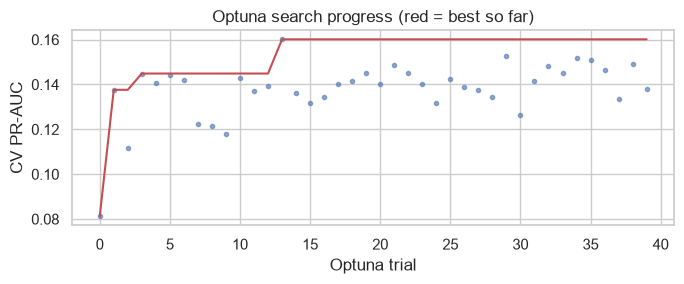

In [43]:
def lgbm_from(p): return LGBMClassifier(objective="binary", n_estimators=p["n_estimators"], learning_rate=p["learning_rate"], num_leaves=p["num_leaves"],
        min_child_samples=p["min_child_samples"], subsample=p["subsample"], subsample_freq=1, colsample_bytree=p["colsample_bytree"], reg_lambda=p["reg_lambda"],
        scale_pos_weight=p["scale_pos_weight"], random_state=SEED, n_jobs=2, verbose=-1, deterministic=True, force_col_wise=True)

def objective(trial):
    p = {"n_estimators": trial.suggest_int("n_estimators", 60, 400), "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
         "num_leaves": trial.suggest_int("num_leaves", 3, 24, log=True), "min_child_samples": trial.suggest_int("min_child_samples", 10, 120, log=True),
         "subsample": trial.suggest_float("subsample", 0.5, 1.0), "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
         "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 50.0, log=True), "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [1, 3, 8, 15, 34])}
    return float(np.mean(cross_val_score(make_pipe("gbm", lgbm_from(p)), Ftr, ytr, cv=cv_splits, scoring="average_precision", n_jobs=1)))

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40, show_progress_bar=False)
print(f"best CV PR-AUC = {study.best_value:.3f}  ({time.time()-t0:.0f}s, {len(study.trials)} trials)\nparams = {study.best_params}")
lgbm_best = make_pipe("gbm", lgbm_from(study.best_params)).fit(Ftr, ytr)
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot([t.value for t in study.trials], ".", alpha=.6); ax.plot(np.maximum.accumulate([t.value for t in study.trials]), "r-")
ax.set_xlabel("Optuna trial"); ax.set_ylabel("CV PR-AUC"); ax.set_title("Optuna search progress (red = best so far)"); plt.tight_layout(); plt.show()

## 12. Calibration and validation comparison
Class-weighted training pushes predicted probabilities far above the true 2.8% base rate, so raw scores cannot be read as risks and a threshold taken from them is not meaningful. We therefore applied **Platt scaling (sigmoid)** fitted on the **out-of-fold training predictions** (`CalibratedClassifierCV(cv=<grouped folds>, ensemble=False)`). Why sigmoid, not isotonic? Platt has two parameters; isotonic is non-parametric and would overfit with only 81 positives. Validation data were never used to fit calibration.

calibrated models fitted in 40s


,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI,Brier
Dummy (prevalence),0.500,0.500–0.500,0.028,0.015–0.043,0.027
Clinical LR (8 risk factors),0.785,0.682–0.886,0.133,0.049–0.323,0.026
Elastic-net LR,0.785,0.670–0.888,0.154,0.048–0.384,0.026
Random forest,0.724,0.601–0.864,0.132,0.043–0.356,0.026
LightGBM,0.712,0.536–0.874,0.186,0.035–0.462,0.027
Soft-vote ensemble,0.778,0.666–0.885,0.194,0.048–0.451,0.026


Brier score BEFORE vs AFTER calibration (lower is better; dummy = 0.0274):


,raw,calibrated
Elastic-net LR,0.0264,0.0262
Random forest,0.0662,0.0262
LightGBM,0.0267,0.0267


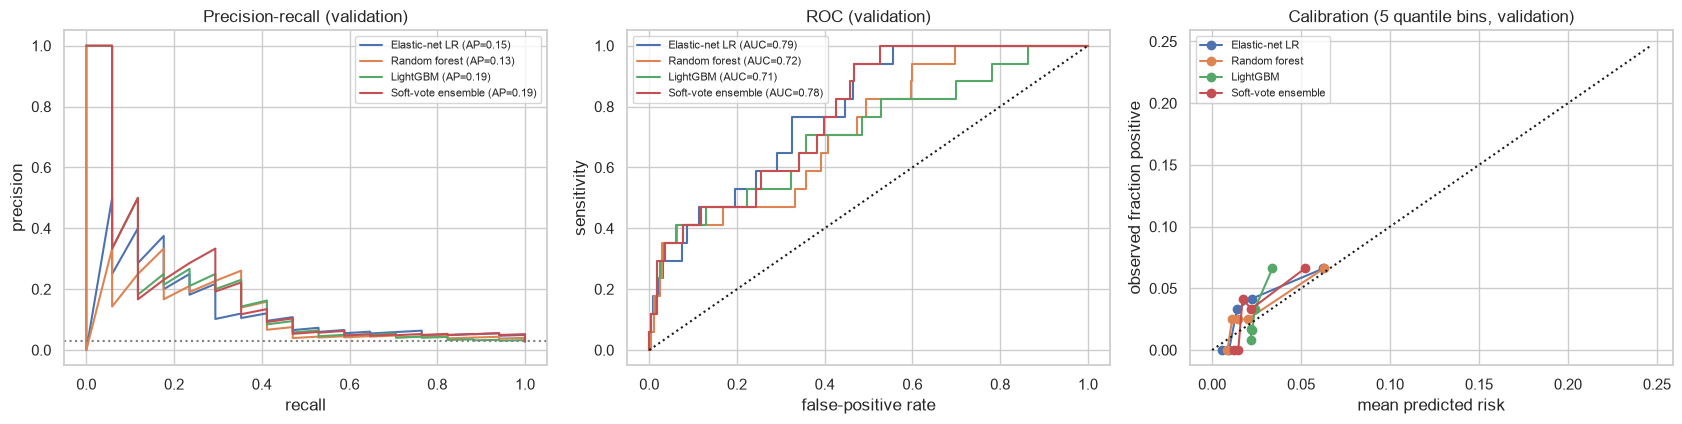

In [44]:
t0 = time.time()
cal = {name: CalibratedClassifierCV(pipe, method="sigmoid", cv=cv_splits, ensemble=False).fit(Ftr, ytr)
       for name, pipe in {"Elastic-net LR": lr_best, "Random forest": rf_best, "LightGBM": lgbm_best}.items()}
print(f"calibrated models fitted in {time.time()-t0:.0f}s")
pva = {k: m.predict_proba(Fva)[:, 1] for k, m in cal.items()}
pva["Soft-vote ensemble"] = np.mean([pva["Elastic-net LR"], pva["Random forest"], pva["LightGBM"]], axis=0)
raw_va = {"Elastic-net LR": lr_best.predict_proba(Fva)[:, 1], "Random forest": rf_best.predict_proba(Fva)[:, 1], "LightGBM": lgbm_best.predict_proba(Fva)[:, 1]}

rows = {"Dummy (prevalence)": res_val["Dummy (prevalence)"], "Clinical LR (8 risk factors)": res_val["Clinical LR (8 risk factors)"]}
for k, p in pva.items(): rows[k] = metrics(yva, p, gva)
VAL = pd.DataFrame(rows).T
display(VAL[["ROC-AUC", "ROC-AUC 95% CI", "PR-AUC", "PR-AUC 95% CI", "Brier"]].astype({"ROC-AUC": float, "PR-AUC": float, "Brier": float}).round(3))
print("Brier score BEFORE vs AFTER calibration (lower is better; dummy = %.4f):" % brier_score_loss(yva, np.full(len(yva), ytr.mean())))
display(pd.DataFrame({"raw": {k: brier_score_loss(yva, v) for k, v in raw_va.items()}, "calibrated": {k: brier_score_loss(yva, pva[k]) for k in raw_va}}).round(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for k, p in pva.items():
    pr, rc, _ = precision_recall_curve(yva, p); ax[0].plot(rc, pr, label=f"{k} (AP={average_precision_score(yva, p):.2f})")
    fpr, tpr, _ = roc_curve(yva, p); ax[1].plot(fpr, tpr, label=f"{k} (AUC={roc_auc_score(yva, p):.2f})")
    fp_, mp_ = calibration_curve(yva, p, n_bins=5, strategy="quantile"); ax[2].plot(mp_, fp_, "o-", label=k)
ax[0].axhline(yva.mean(), color="gray", ls=":"); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall (validation)"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("false-positive rate"); ax[1].set_ylabel("sensitivity"); ax[1].set_title("ROC (validation)"); ax[1].legend(fontsize=8)
mx = max(max(v.max() for v in pva.values()), .2); ax[2].plot([0, mx], [0, mx], "k:"); ax[2].set_xlabel("mean predicted risk"); ax[2].set_ylabel("observed fraction positive")
ax[2].set_title("Calibration (5 quantile bins, validation)"); ax[2].legend(fontsize=8); plt.tight_layout(); plt.show()

## 13. Model selection (pre-specified rule) and the decision threshold, both using the validation set only
**Selection rule, written before looking at test data:** rank the candidates by validation **PR-AUC**. Because validation has only 17 positives, differences smaller than one bootstrap standard deviation are not real evidence, so *among all models within one SD of the best, choose the simplest* (order: logistic regression < random forest < LightGBM < ensemble). This is the "one-standard-error / parsimony" idea applied to model families; it protects against crowning a lucky model.

**Threshold.** The default 0.5 is "a default, not a law". In screening the two errors are not equally bad: a **missed** diabetic (false negative) goes untreated and risks complications, while a **false alarm** costs one confirmatory fasting-glucose test. With calibrated probabilities, decision theory gives the optimal rule in closed form: *refer if p ≥ C_FP / (C_FP + C_FN)*. We assume **C_FN : C_FP = 10 : 1** (an explicit, adjustable assumption; a ministry would set it), so **t\* = 1/11 ≈ 0.091**, about 3× the base rate. We reported the empirical optimum on validation and the sensitivity to the cost ratio as checks, but used the theoretical t\* (no fitting to 17 positives).

                    val PR-AUC  within_1SD_of_best
Elastic-net LR           0.154                True
Random forest            0.132                True
LightGBM                 0.186                True
Soft-vote ensemble       0.194                True
best on validation: Soft-vote ensemble (PR-AUC 0.194, bootstrap SD 0.106);  models within 1 SD: ['Elastic-net LR', 'Random forest', 'LightGBM', 'Soft-vote ensemble']  =>  CHAMPION (simplest of those): Elastic-net LR


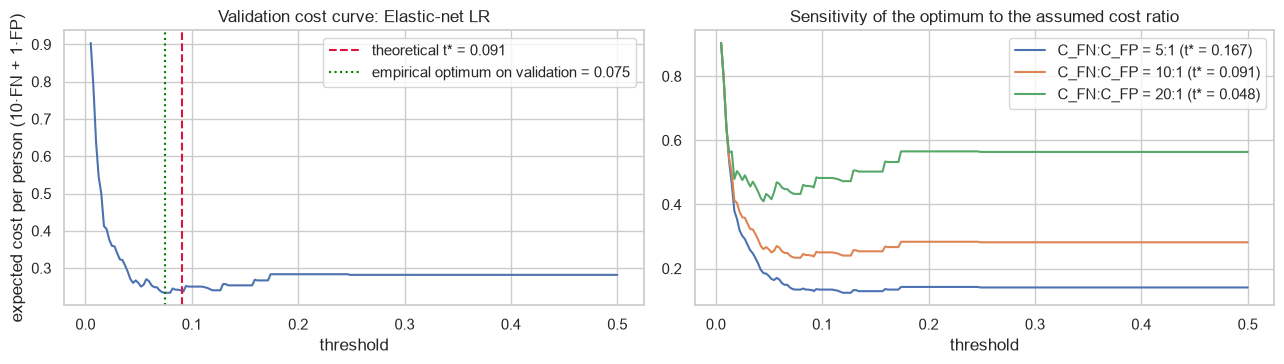

,threshold,referred_pct,sensitivity,specificity,PPV,NPV,TP,FN,FP,TN,people_referred_per_case_found
"t* (10:1 cost, USED)",0.091,3.151,0.235,0.974,0.211,0.978,4.0,13.0,15.0,571.0,4.750
empirical optimum (val),0.075,4.312,0.294,0.964,0.192,0.979,5.0,12.0,21.0,565.0,5.200
threshold giving 80% sensitivity (val),0.015,45.605,0.824,0.555,0.051,0.991,14.0,3.0,261.0,325.0,19.643
refer top 20% by risk (val),0.033,20.066,0.471,0.807,0.066,0.981,8.0,9.0,113.0,473.0,15.125


FINAL RULE (frozen before test): champion = Elastic-net LR; refer for a confirmatory glucose test if calibrated risk ≥ 0.091


In [45]:
cand = ["Elastic-net LR", "Random forest", "LightGBM", "Soft-vote ensemble"]; complexity = dict(zip(cand, range(1, 5)))
ap = {k: float(VAL.loc[k, "PR-AUC"]) for k in cand}; top = max(ap, key=ap.get); sd_top = float(VAL.loc[top, "PR-AUC SD"])
within = [k for k in cand if ap[k] >= ap[top] - sd_top]; CHAMPION = min(within, key=complexity.get)
print(pd.Series(ap).round(3).to_frame("val PR-AUC").assign(within_1SD_of_best=lambda d: d.index.isin(within)).to_string())
print(f"best on validation: {top} (PR-AUC {ap[top]:.3f}, bootstrap SD {sd_top:.3f});  models within 1 SD: {within}  =>  CHAMPION (simplest of those): {CHAMPION}")

def predict_champion(F):
    ps = {k: m.predict_proba(F)[:, 1] for k, m in cal.items()}
    return np.mean(list(ps.values()), axis=0) if CHAMPION == "Soft-vote ensemble" else ps[CHAMPION]

def op_point(yv, pv, t):
    pred = pv >= t; tn, fp, fn, tp = confusion_matrix(yv, pred, labels=[0, 1]).ravel()
    return dict(threshold=t, referred_pct=100 * pred.mean(), sensitivity=tp / max(tp + fn, 1), specificity=tn / max(tn + fp, 1),
                PPV=tp / (tp + fp) if tp + fp else np.nan, NPV=tn / max(tn + fn, 1), TP=tp, FN=fn, FP=fp, TN=tn, people_referred_per_case_found=(tp + fp) / tp if tp else np.nan)

C_FN, C_FP = 10, 1; T_STAR = C_FP / (C_FP + C_FN)
pv = predict_champion(Fva)
grid = np.unique(np.r_[np.linspace(0.005, 0.5, 200), T_STAR])
cost = np.array([(C_FN * op_point(yva, pv, t)["FN"] + C_FP * op_point(yva, pv, t)["FP"]) / len(yva) for t in grid])
t_emp = grid[cost.argmin()]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(grid, cost); ax[0].axvline(T_STAR, color="crimson", ls="--", label=f"theoretical t* = {T_STAR:.3f}"); ax[0].axvline(t_emp, color="green", ls=":", label=f"empirical optimum on validation = {t_emp:.3f}")
ax[0].set_xlabel("threshold"); ax[0].set_ylabel("expected cost per person (10·FN + 1·FP)"); ax[0].set_title(f"Validation cost curve: {CHAMPION}"); ax[0].legend()
for r_ in (5, 10, 20): ax[1].plot(grid, [(r_ * op_point(yva, pv, t)["FN"] + op_point(yva, pv, t)["FP"]) / len(yva) for t in grid], label=f"C_FN:C_FP = {r_}:1 (t* = {1/(1+r_):.3f})")
ax[1].set_xlabel("threshold"); ax[1].set_title("Sensitivity of the optimum to the assumed cost ratio"); ax[1].legend(); plt.tight_layout(); plt.show()

fpr_, tpr_, thr_ = roc_curve(yva, pv); t_sens80 = thr_[np.argmax(tpr_ >= 0.80)]
ops = pd.DataFrame({"t* (10:1 cost, USED)": op_point(yva, pv, T_STAR), "empirical optimum (val)": op_point(yva, pv, t_emp),
                    "threshold giving 80% sensitivity (val)": op_point(yva, pv, t_sens80),
                    "refer top 20% by risk (val)": op_point(yva, pv, np.quantile(pv, 0.80))}).T
display(ops.round(3))
THRESHOLD = float(T_STAR)
print(f"FINAL RULE (frozen before test): champion = {CHAMPION}; refer for a confirmatory glucose test if calibrated risk ≥ {THRESHOLD:.3f}")

## 14. Proving there is no leakage
Three independent checks, each of which would *fail loudly* if something were wrong.
1. **Label-shuffle canary.** Re-run the whole pipeline with the training labels randomly permuted. If any step smuggled outcome information from validation into training, the AUC would stay above 0.5. It must collapse to ≈ 0.5.
2. **Leakage ablation (what leakage looks like).** Add the excluded tiers back and watch performance jump. This shows both *that* the exclusion matters and *how big* the inflation would have been.
3. **Structural audit.** No forbidden column in the feature list; PSUs disjoint; all fitted statistics come from the training rows (printed in sections 5, 9).

In [46]:
from sklearn.base import clone
rs = np.random.RandomState(SEED); can = []
for i in range(5):
    yp = pd.Series(rs.permutation(ytr.values))
    m = clone(lr_best).fit(Ftr, yp); can.append(roc_auc_score(yva, m.predict_proba(Fva)[:, 1]))
print(f"1. LABEL-SHUFFLE CANARY: validation ROC-AUC with permuted training labels = {np.mean(can):.3f} ± {np.std(can):.3f}  (5 shuffles; expected ≈ 0.50)   -> {'PASS' if abs(np.mean(can)-0.5) < 0.1 else 'CHECK'}")

LRB = {k.replace("model__", ""): v for k, v in lr_search.best_params_.items()}
counsel = C("H20a", "H20b", "H20c", "H20d", "H20e", "H20f", "H20g", "H20h")
def extra_frame(X):
    med = (X[col("B6")].eq(1) | X[col("H8")].eq(1) | X[col("H9")].eq(1)).astype(float)
    return pd.DataFrame({"told_diabetes": X[col("H7a")].eq(1).astype(float), "blood_sugar_ever_measured": X[col("H6")].fillna(0),
                         "on_diabetes_medication": med, "fasting_glucose": X[col("B5")]}).join(X[counsel])
EX_tr, EX_va = extra_frame(Xtr_raw), extra_frame(Xva_raw)
def val_lr_with(extra_bin=(), extra_num=()):
    cols = list(extra_bin) + list(extra_num)
    Xt = pd.concat([Ftr, EX_tr[cols]], axis=1) if cols else Ftr; Xv = pd.concat([Fva, EX_va[cols]], axis=1) if cols else Fva
    pipe = Pipeline([("prep", make_prep("linear", extra_num=extra_num, extra_bin=extra_bin)),
                     ("model", LogisticRegression(solver="saga", max_iter=3000, tol=1e-3, random_state=SEED, **LRB))]).fit(Xt, ytr)
    p = pipe.predict_proba(Xv)[:, 1]; return roc_auc_score(yva, p), average_precision_score(yva, p)
abl = pd.DataFrame({
    "our feature set (no leakage)": val_lr_with(),
    "+ counselling block (tier C)": val_lr_with(extra_bin=counsel),
    "+ diagnosis pathway (tier B): told diabetic, sugar ever measured": val_lr_with(extra_bin=["told_diabetes", "blood_sugar_ever_measured"]),
    "+ diabetes medication (tier A)": val_lr_with(extra_bin=["on_diabetes_medication"]),
    "+ fasting glucose (tier A)": val_lr_with(extra_num=["fasting_glucose"]),
}, index=["val ROC-AUC", "val PR-AUC"]).T
display(abl.round(3))
print("2. ABLATION: tier A (glucose, medication) is the label read back to us: the score jumps to near-perfect. Tiers B and C move performance only a little in THIS sample because few respondents had ever been tested or counselled "
      f"({EX_tr.blood_sugar_ever_measured.mean():.0%} ever had sugar measured, {EX_tr.told_diabetes.mean():.1%} say they were told they are diabetic), so they are excluded on causal grounds (consequences of diagnosis), not because they happened to help here.")
assert not (set(FEATURES) & FORBIDDEN) and not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("3. STRUCTURAL AUDIT: PASS (no forbidden column among the", len(FEATURES), "features; PSUs disjoint across splits; preprocessing fitted on train only)")

1. LABEL-SHUFFLE CANARY: validation ROC-AUC with permuted training labels = 0.421 ± 0.068  (5 shuffles; expected ≈ 0.50)   -> PASS


,val ROC-AUC,val PR-AUC
our feature set (no leakage),0.785,0.154
+ counselling block (tier C),0.776,0.140
"+ diagnosis pathway (tier B): told diabetic, sugar ever measured",0.792,0.183
+ diabetes medication (tier A),0.800,0.169
+ fasting glucose (tier A),0.933,0.776


2. ABLATION: tier A (glucose, medication) is the label read back to us: the score jumps to near-perfect. Tiers B and C move performance only a little in THIS sample because few respondents had ever been tested or counselled (16% ever had sugar measured, 1.7% say they were told they are diabetic), so they are excluded on causal grounds (consequences of diagnosis), not because they happened to help here.
3. STRUCTURAL AUDIT: PASS (no forbidden column among the 95 features; PSUs disjoint across splits; preprocessing fitted on train only)


## 15. Final, one-time evaluation on the held-out test set
Everything frozen: features, preprocessing, hyper-parameters, calibration, champion and threshold were all fixed on train/validation. The test set was scored **once**. Intervals are PSU-cluster bootstrap 95% CIs. The other models are shown only for context (they cannot change the decision).

,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI,Brier
Dummy (prevalence),0.500,0.500–0.500,0.029,0.016–0.042,0.028
Clinical LR (8 risk factors),0.671,0.543–0.773,0.089,0.035–0.212,0.028
Elastic-net LR ← CHAMPION,0.690,0.533–0.832,0.113,0.037–0.263,0.027
Random forest,0.716,0.603–0.829,0.086,0.038–0.186,0.027
LightGBM,0.730,0.582–0.864,0.148,0.064–0.293,0.027
Soft-vote ensemble,0.706,0.564–0.844,0.124,0.048–0.280,0.027


Test-set behaviour at alternative thresholds that were all derived from VALIDATION only (shown for transparency; NOT used to choose the rule):


,threshold,referred_pct,sensitivity,specificity,PPV,NPV,TP,FN,FP,TN,people_referred_per_case_found
"t* = 0.091 (USED, frozen)",0.091,5.079,0.333,0.958,0.188,0.980,6.0,12.0,26.0,586.0,5.333
validation-derived 80%-sensitivity threshold,0.015,52.063,0.722,0.485,0.040,0.983,13.0,5.0,315.0,297.0,25.231
validation-derived 'refer top 20%' threshold,0.033,22.381,0.500,0.784,0.064,0.982,9.0,9.0,132.0,480.0,15.667



TEST operating point of Elastic-net LR at threshold 0.091 (frozen on validation):
  sensitivity 0.33  (95% CI 0.12–0.56)   specificity 0.96  (CI 0.94–0.97)
  PPV 0.188  NPV 0.980   referred 5.1% of people;  ≈ 5.3 confirmatory tests per diabetic found;  TP=6 FN=12 FP=26 TN=586


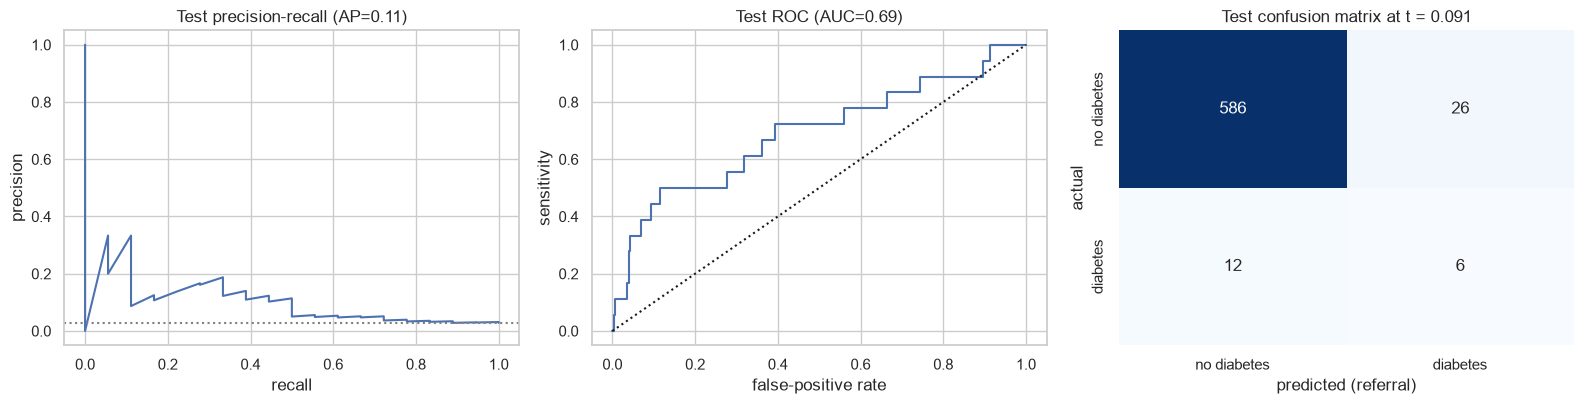

Test calibration (5 quantile bins): mean predicted vs observed rate: [(np.float64(0.006), np.float64(0.016)), (np.float64(0.01), np.float64(0.016)), (np.float64(0.016), np.float64(0.016)), (np.float64(0.026), np.float64(0.024)), (np.float64(0.084), np.float64(0.071))]


In [47]:
pte = {k: m.predict_proba(Fte)[:, 1] for k, m in cal.items()}; pte["Soft-vote ensemble"] = np.mean([pte["Elastic-net LR"], pte["Random forest"], pte["LightGBM"]], axis=0)
pte_ch = pte[CHAMPION]
trows = {"Dummy (prevalence)": metrics(yte, np.full(len(yte), ytr.mean()), gte)}
trows["Clinical LR (8 risk factors)"] = metrics(yte, clin.predict_proba(Fte[clin_cols])[:, 1], gte)
for k in cand: trows[k + (" ← CHAMPION" if k == CHAMPION else "")] = metrics(yte, pte[k], gte)
TEST = pd.DataFrame(trows).T
display(TEST[["ROC-AUC", "ROC-AUC 95% CI", "PR-AUC", "PR-AUC 95% CI", "Brier"]].astype({"ROC-AUC": float, "PR-AUC": float, "Brier": float}).round(3))

op = op_point(yte, pte_ch, THRESHOLD)
alt = {"t* = 0.091 (USED, frozen)": THRESHOLD, "validation-derived 80%-sensitivity threshold": float(t_sens80), "validation-derived 'refer top 20%' threshold": float(np.quantile(pv, 0.80))}
print("Test-set behaviour at alternative thresholds that were all derived from VALIDATION only (shown for transparency; NOT used to choose the rule):")
display(pd.DataFrame({k: op_point(yte, pte_ch, t) for k, t in alt.items()}).T.round(3))
sens_b = cluster_bootstrap(yte, pte_ch, gte, lambda a, b: op_point(a, b, THRESHOLD)["sensitivity"]); spec_b = cluster_bootstrap(yte, pte_ch, gte, lambda a, b: op_point(a, b, THRESHOLD)["specificity"])
ppv_b = cluster_bootstrap(yte, pte_ch, gte, lambda a, b: np.nan_to_num(op_point(a, b, THRESHOLD)["PPV"]))
print(f"\nTEST operating point of {CHAMPION} at threshold {THRESHOLD:.3f} (frozen on validation):")
print(f"  sensitivity {op['sensitivity']:.2f}  (95% CI {np.percentile(sens_b,2.5):.2f}–{np.percentile(sens_b,97.5):.2f})   specificity {op['specificity']:.2f}  (CI {np.percentile(spec_b,2.5):.2f}–{np.percentile(spec_b,97.5):.2f})")
print(f"  PPV {op['PPV']:.3f}  NPV {op['NPV']:.3f}   referred {op['referred_pct']:.1f}% of people;  ≈ {op['people_referred_per_case_found']:.1f} confirmatory tests per diabetic found;  TP={op['TP']} FN={op['FN']} FP={op['FP']} TN={op['TN']}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
pr, rc, _ = precision_recall_curve(yte, pte_ch); ax[0].plot(rc, pr); ax[0].axhline(yte.mean(), color="gray", ls=":"); ax[0].set_title(f"Test precision-recall (AP={average_precision_score(yte, pte_ch):.2f})"); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
fpr, tpr, _ = roc_curve(yte, pte_ch); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_title(f"Test ROC (AUC={roc_auc_score(yte, pte_ch):.2f})"); ax[1].set_xlabel("false-positive rate"); ax[1].set_ylabel("sensitivity")
sns.heatmap([[op["TN"], op["FP"]], [op["FN"], op["TP"]]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[2], xticklabels=["no diabetes", "diabetes"], yticklabels=["no diabetes", "diabetes"]); ax[2].set_xlabel("predicted (referral)"); ax[2].set_ylabel("actual"); ax[2].set_title(f"Test confusion matrix at t = {THRESHOLD:.3f}")
plt.tight_layout(); plt.show()
fp_, mp_ = calibration_curve(yte, pte_ch, n_bins=5, strategy="quantile")
print("Test calibration (5 quantile bins): mean predicted vs observed rate:", [(round(a, 3), round(b, 3)) for a, b in zip(mp_, fp_)])

### 15.1 How to read these results honestly
* **Discrimination is moderate, not strong.** Validation ROC-AUC ≈ 0.79 but test ≈ 0.69, with overlapping 95% intervals. With only 17 positives in each set a swing of this size is within sampling noise, and the validation estimate is the optimistic one because the model was *selected* on it. The test figure is the honest one.
* **The complex models do not clearly beat the 8-variable clinical baseline** (their PR-AUC intervals overlap heavily). The 230-column questionnaire adds little beyond age, adiposity and blood pressure, which is a real and publishable finding: *cheap risk factors carry most of the signal*.
* **The operating point is a policy choice.** The pre-specified 10:1 cost ratio gives a high-specificity, low-sensitivity rule (few referrals, most diabetics missed). A screening programme that wants ≥ 80% sensitivity must accept referring about half of people for a confirmatory test; the table above shows what each choice costs on test data. The ratio was an assumption, and *changing it after seeing test results would be a new, post-hoc decision*, which is why the frozen rule is reported as is.
* **Calibration is reasonable** (predicted ≈ observed in the bins above), so the probabilities themselves are usable as individual risk estimates even though the ranking is only moderately sharp.

## 16. Explainability: what drives the predictions?
Clinicians need to know *why* a person is flagged (and to check the model is using sensible, non-leaky signals). We showed the **standardised elastic-net coefficients** (direction and relative strength; odds ratio per 1 SD) and **SHAP values** for the LightGBM model (additive contribution of each feature to each individual's risk, computed on validation data).

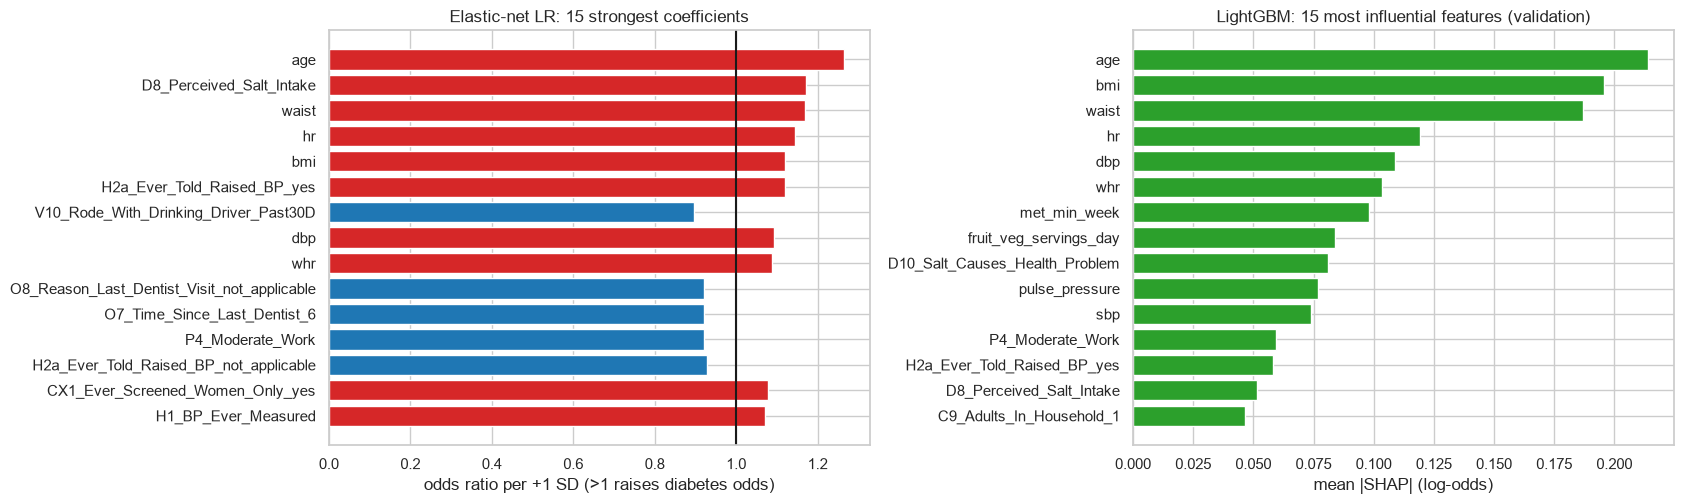

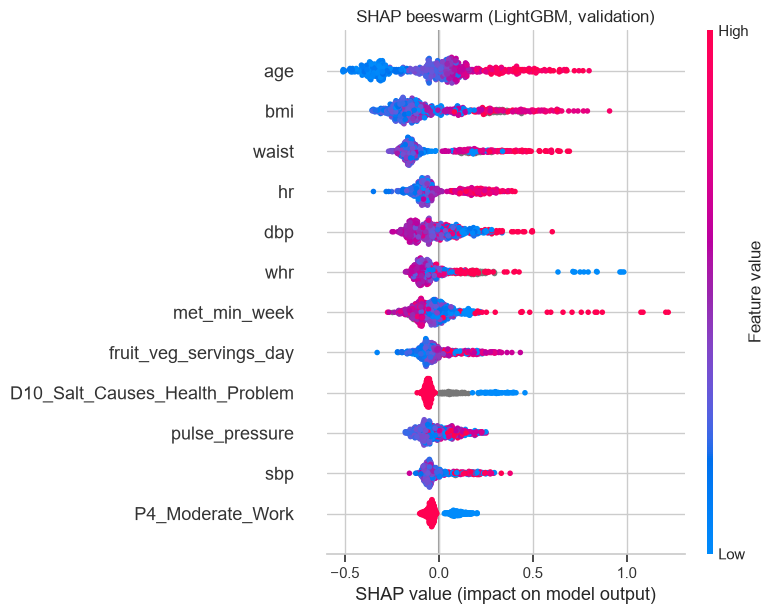

In [48]:
import shap
clean_name = lambda n: re.sub(r"^(meas|num|ord|bin|ind|cat)__", lambda m: {"ind": "MISSING:", "cat": ""}.get(m.group(1), ""), n)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.2))
ax[0].barh([clean_name(n) for n in top.index][::-1], np.exp(top.values)[::-1], color=["tab:red" if v > 0 else "tab:blue" for v in top.values][::-1]); ax[0].axvline(1, color="k")
ax[0].set_xlabel("odds ratio per +1 SD (>1 raises diabetes odds)"); ax[0].set_title("Elastic-net LR: 15 strongest coefficients")
Xv_t = lgbm_best["prep"].transform(Fva); names_g = [clean_name(n) for n in lgbm_best["prep"].get_feature_names_out()]
sv = shap.TreeExplainer(lgbm_best["model"]).shap_values(Xv_t); sv = sv[1] if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean(axis=0), index=names_g).sort_values(ascending=False).head(15)
ax[1].barh(imp.index[::-1], imp.values[::-1], color="tab:green"); ax[1].set_xlabel("mean |SHAP| (log-odds)"); ax[1].set_title("LightGBM: 15 most influential features (validation)")
plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(sv, Xv_t, feature_names=names_g, max_display=12, show=False); plt.title("SHAP beeswarm (LightGBM, validation)"); plt.tight_layout(); plt.show()

## 17. Robustness and fairness checks (test set, champion model)
1. **Subgroup performance** (sex, residence, age): a screening tool must not work only for one group. Positives per subgroup are tiny, so these are *indicative*, not conclusive.
2. **Survey-weighted performance**: STEPS over/under-samples some groups; weighting by `Weight_Step3` shows what the metrics would look like for the target population.

In [49]:
tw = raw.loc[lab, "Weight_Step3"].reset_index(drop=True).iloc[idx["test"]].reset_index(drop=True)
rows = []
for name, mask in {"all": np.ones(len(yte), bool), "women": Fte.female.eq(1).values, "men": Fte.female.eq(0).values, "urban": Fte.urban.eq(1).values, "rural": Fte.urban.eq(0).values,
                   "age < 40": Fte.age.lt(40).values, "age ≥ 40": Fte.age.ge(40).values}.items():
    yy, pp = yte[mask], pte_ch[mask]; o = op_point(yy, pp, THRESHOLD)
    rows.append((name, int(mask.sum()), int(yy.sum()), roc_auc_score(yy, pp) if yy.sum() >= 3 else np.nan, o["sensitivity"] if yy.sum() else np.nan, o["referred_pct"]))
display(pd.DataFrame(rows, columns=["subgroup", "n", "positives", "ROC-AUC", "sensitivity@t*", "% referred"]).set_index("subgroup").round(3))
print(f"Survey-weighted test ROC-AUC = {roc_auc_score(yte, pte_ch, sample_weight=tw):.3f}  vs unweighted {roc_auc_score(yte, pte_ch):.3f};  weighted PR-AUC = {average_precision_score(yte, pte_ch, sample_weight=tw):.3f}")

,n,positives,ROC-AUC,sensitivity@t*,% referred
subgroup,,,,,
all,630,18,0.690,0.333,5.079
women,400,10,0.893,0.600,6.750
men,230,8,0.496,0.000,2.174
urban,319,9,0.751,0.444,6.270
rural,311,9,0.636,0.222,3.859
age < 40,396,5,0.610,0.000,0.000
age ≥ 40,234,13,0.649,0.462,13.675


Survey-weighted test ROC-AUC = 0.546  vs unweighted 0.690;  weighted PR-AUC = 0.034


## 18. Limitations and threats to validity (read before trusting any number)
* **The model is weak, and the headline numbers flatter it.** On the held-out test set the champion reaches ROC-AUC 0.690 and PR-AUC 0.113, barely above the 8-variable clinical baseline (0.671 / 0.089) with heavily overlapping 95% intervals. **Survey-weighted** test ROC-AUC is only **0.546** (weighted PR-AUC 0.034, close to the prevalence), so for the population the survey represents the model ranks people little better than chance.
* **It does not work for men.** Test ROC-AUC for men is **0.496** (8 positives) and the frozen rule flags none of them (sensitivity 0.00), against 0.893 for women. Age < 40 is similarly poor (AUC 0.610, no positives flagged). These subgroups are small, but the direction is a fairness problem, not noise to dismiss.
* **Most diabetics are missed at the chosen threshold.** At t* = 0.091 the test sensitivity is **0.33** (6 of 18 found, 95% CI 0.12–0.56). Reaching ~80% sensitivity needs a threshold near 0.015, which refers about half of all adults for a glucose test.
* **Few positives.** 81 / 17 / 18 positives in train / validation / test. Every metric has a wide interval (see CIs); model rankings on validation are weak evidence, which is why the selection rule favours the simpler model. Conclusions should be about *orders of magnitude* (is it far better than the clinical baseline?), not third decimals.
* **Label noise.** A single fasting glucose ≥ 7.0 is the survey definition, but clinical diagnosis normally needs confirmation. Some positives would not be confirmed and some diet-controlled diabetics (27 here) are labelled 0.
* **Selection into Step 3.** 7% of respondents have no glucose measurement and non-fasters were excluded; if they differ in diabetes risk the sample is not perfectly representative (weights partly address this in section 17).
* **Cross-sectional, 2015.** There is no time dimension; the PSU-grouped split is our guard against optimistic estimates, but there is **no external validation** (another year or another country's STEPS) and no prospective test.
* **Health-system contact proxies.** Kept variables such as BP history, statin and aspirin use correlate with contact with services; their influence should be monitored.
* **Validation-to-test drop.** AUC fell from ≈ 0.79 to ≈ 0.69; the age < 40 subgroup has only 5 positives (AUC meaningless there). More data, or pooling STEPS rounds, is the main route to a stronger model.
* **Cost ratio.** The 10:1 assumption sets the threshold; it should be replaced by a ministry-specific value (the notebook makes this a one-line change).
* **Imputation choices.** Structural fills and indicators are justified by skip-logic evidence, but a different treatment of the 20–80% band is a legitimate alternative.

**Deployment.** The cleaning and feature code and the frozen pipeline were packaged into a FastAPI service with Pydantic validation, containerised with Docker/docker-compose, documented in README.md and AI Use.md, and runs were logged with MLflow.

In [50]:
import joblib, os
os.makedirs("diabetes_model", exist_ok=True)
bundle = {"champion": CHAMPION, "threshold": THRESHOLD, "cost_ratio": (C_FN, C_FP), "calibrated_models": cal, "features": FEATURES,
          "struct_rules": STRUCT_RULES, "drop80": DROP80, "universe": UNIVERSE, "type_lists": dict(ENG_MEAS=ENG_MEAS, NUM_F=NUM_F, ORD_COLS=ORD_COLS, BIN_F=BIN_F, CAT_F=CAT_F),
          "split_seed": int(best_seed), "sklearn": sklearn.__version__}
joblib.dump(bundle, "diabetes_model/model_bundle.joblib")
json.dump({"champion": CHAMPION, "threshold": THRESHOLD, "n_features": len(FEATURES), "validation": VAL[["ROC-AUC", "PR-AUC", "Brier"]].astype(float).round(4).to_dict("index"),
           "test": TEST[["ROC-AUC", "PR-AUC", "Brier"]].astype(float).round(4).to_dict("index")}, open("diabetes_model/model_card.json", "w"), indent=2)
print("saved diabetes_model/model_bundle.joblib and diabetes_model/model_card.json")

saved diabetes_model/model_bundle.joblib and dm/model_card.json


In [53]:
import hashlib, os, platform, tempfile
import mlflow
from pathlib import Path

TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "sqlite:///mlruns/mlflow.db")   # docker-compose server: http://localhost:5000
if TRACKING_URI.startswith("sqlite:///"): Path(TRACKING_URI[10:]).parent.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment("diabetes-screening-steps2015")

def _clean(d): return {k.replace("model__", "").replace("param_", ""): (v if isinstance(v, (int, float, str, bool)) or v is None else str(v)) for k, v in d.items()}
def _slug(s): return "".join(ch if ch.isalnum() else "_" for ch in str(s)).strip("_").lower()
_TEST = TEST.rename(index=lambda s: str(s).replace(" ← CHAMPION", ""))      # the notebook marks the champion row in TEST
_sha = hashlib.sha256(Path("diabetes_model/model_bundle.joblib").read_bytes()).hexdigest()

with mlflow.start_run(run_name=f"notebook-{CHAMPION}-seed{int(best_seed)}") as run:
    mlflow.set_tags({"stage": "training", "source": "notebook", "champion": CHAMPION, "dataset": "WHO STEPS Kenya 2015", "unit_of_split": "PSU (cluster)",
                     "python": platform.python_version(), "bundle_sha256": _sha[:16]})
    mlflow.log_params({"split_seed": int(best_seed), "random_state": SEED, "n_train": len(ytr), "n_val": len(yva), "n_test": len(yte), "n_pos_train": int(ytr.sum()),
                       "n_pos_val": int(yva.sum()), "n_pos_test": int(yte.sum()), "n_features": len(FEATURES), "cost_ratio_FN_to_FP": f"{C_FN}:{C_FP}",
                       "referral_threshold": round(float(THRESHOLD), 6), "cv_scoring": "average_precision (PR-AUC)", "calibration": "Platt on out-of-fold predictions",
                       "sklearn": sklearn.__version__, "bundle_sha256": _sha})

    # 1) every hyper-parameter candidate the searches tried, grouped under one run per model family
    searches = {}
    if "lr_search" in globals(): searches["Elastic-net LR (grid)"] = pd.DataFrame(lr_search.cv_results_)
    if "rf_search" in globals(): searches["Random forest (random search)"] = pd.DataFrame(rf_search.cv_results_)
    if "study" in globals():
        t = study.trials_dataframe(); t = t[t.state == "COMPLETE"]
        searches["LightGBM (Optuna TPE)"] = pd.DataFrame({"params": [{k: v for k, v in tr.params.items()} for tr in study.trials if tr.state.name == "COMPLETE"],
                                                         "mean_test_score": [tr.value for tr in study.trials if tr.state.name == "COMPLETE"]})
    for name, df in searches.items():
        with mlflow.start_run(run_name=f"search: {name}", nested=True):
            mlflow.set_tag("kind", "hyperparameter_search")
            score = df["mean_test_score"]; mlflow.log_metrics({"cv_pr_auc_best": float(score.max()), "cv_pr_auc_median": float(score.median()), "n_candidates": float(len(df))})
            with tempfile.TemporaryDirectory() as d:
                df.to_csv(Path(d) / "cv_results.csv", index=False); mlflow.log_artifact(str(Path(d) / "cv_results.csv"), "search")
            for i, r in df.sort_values("mean_test_score", ascending=False).head(10).reset_index(drop=True).iterrows():           # top-10 candidates as their own runs
                with mlflow.start_run(run_name=f"candidate {i+1}", nested=True):
                    mlflow.log_params(_clean(r["params"]) if "params" in r else {}); mlflow.log_metric("cv_pr_auc_mean", float(r["mean_test_score"]))
                    if "std_test_score" in r: mlflow.log_metric("cv_pr_auc_std", float(r["std_test_score"]))

    # 2) final models: validation and test metrics side by side
    for name in VAL.index:
        with mlflow.start_run(run_name=str(name), nested=True):
            mlflow.set_tags({"model": str(name), "is_champion": str(name == CHAMPION), "kind": "final_model"})
            for m in ("ROC-AUC", "PR-AUC", "Brier"):
                mlflow.log_metric(f"val_{_slug(m)}", float(VAL.loc[name, m]))
                if name in _TEST.index: mlflow.log_metric(f"test_{_slug(m)}", float(_TEST.loc[name, m]))
    for m in ("ROC-AUC", "PR-AUC", "Brier"):
        mlflow.log_metric(f"val_{_slug(m)}", float(VAL.loc[CHAMPION, m])); mlflow.log_metric(f"test_{_slug(m)}", float(_TEST.loc[CHAMPION, m]))

    # the frozen referral rule evaluated on the held-out test set (variable `op` from the threshold cell)
    if "op" in globals():
        for k in ("referred_pct", "sensitivity", "specificity", "PPV", "NPV", "TP", "FN", "FP", "TN"): mlflow.log_metric(f"test_frozen_{k}", float(op[k]))

    # 3) artefacts: the exact files the API serves
    mlflow.log_artifact("diabetes_model/model_bundle.joblib", "model_files"); mlflow.log_artifact("diabetes_model/model_card.json", "model_files")
    mlflow.log_text("\n".join(FEATURES), "model_files/features.txt")
    print(f"MLflow run {run.info.run_id} logged to {TRACKING_URI}")

MLflow run f43b069e63dc4f14b1dd6161382aac26 logged to sqlite:///mlruns/mlflow.db
